# Лабораторная работа №2

## Нейросетевой перевод на базе Hugging Face Transformers (MarianMT, NLLB)

**ФИО студента:** Зайцева Алёна Александровна
**Группа:** ИНФА-221
**Вариант:** 4 (тема модуля из ЛР № 1: Фармацевтика и клинические исследования)

---

**Цель:** развернуть NMT-пайплайн, исследовать субсловную токенизацию, батчинг, условную
кросс-энтропию и cross-attention, сравнить специализированную EN→RU модель **MarianMT**
с многоязычной **NLLB**.

**Максимум: 20 баллов**

| Критерий | Состав | Баллы |
|---|---|---:|
| Работоспособность пайплайна | MarianMT — 2 · NLLB — 2 · batching/loss/attention — 2 | **6** |
| Корректность лингвистической обработки | языковые коды и токенизация — 2 · объём корпуса (120+ сегментов, 100+ терминов) — 1 · glossary QA — 2 | **5** |
| Анализ ошибок и аргументация | 5+ различий — 2 · интерпретация loss/attention — 2 · вывод — 1 | **5** |
| Оформление и воспроизводимость | результаты и графики — 1 · README — 1 · зависимости — 1 · структура — 1 | **4** |

---

### Порядок выполнения

1. **Runtime → Change runtime type → T4 GPU.** Без GPU перевод 120 сегментов двумя моделями
   займёт часы.
2. Выполните блоки 0–1 (установка, окружение).
3. Блок 2 — подключите **свои** файлы из ЛР № 1 (`segments_en.csv`, `glossary.csv`,
   `aligned_reference.csv`) и убедитесь, что проверка объёма даёт «ГОТОВО».
4. Реализуйте функции в блоках 3–8 вместо маркеров `# TODO`.
5. Запустите блок 9 — все автотесты должны пройти без `AssertionError`.
6. Выполните блоки 10–15: перевод корпуса, QA, сравнение, **графики**, отчёт.
7. Заполните вручную колонки `preferred` и `comment` — автоматический выбор модели их не
   заменяет.

### Обязательный минимум

| Требование | Значение |
|---|---|
| Сегментов в корпусе, переведённых **каждой** моделью | **120+** |
| Терминов в глоссарии, разобранных токенизаторами | **100+** |
| Пар `source` / `reference` для кросс-энтропии | 5+ |
| Пар для анализа cross-attention | 2+ |
| Режимы инференса | последовательный и пакетный |
| Содержательных различий с аргументацией | 5+ |
| Графиков в отчёте | 4+ |

> Если в ЛР № 1 корпус меньше, расширьте исходный учебный модуль и глоссарий до требуемого
> объёма **до** начала работы: все дальнейшие выводы опираются на статистику, а на 15
> сегментах она недостоверна.

### Две особенности актуальных версий библиотек

* **`attn_implementation="eager"`.** В `transformers` 5.x модели по умолчанию используют
  ускоренное внимание (SDPA/Flash), которое не сохраняет веса: `outputs.cross_attentions`
  окажется пустым, и блок 7 упадёт с `IndexError: tuple index out of range`.
* **Предупреждение `max_new_tokens` / `max_length`.** Безобидно (приоритет у
  `max_new_tokens`), но зашумляет вывод — логирование понижается в блоке 1.

## Блок 0. Установка зависимостей

`torch` в Colab предустановлен. Ставим `transformers`, `sentencepiece` (нужен токенизатору
NLLB) и `sacremoses` (предобработка MarianMT).

In [1]:
!pip install -q "transformers>=4.40" sentencepiece sacremoses

## Блок 1. Окружение и структура каталогов

Ячейка готова — менять её не нужно. Зафиксированное зерно и вывод версий обязательны для
воспроизводимости (критерий 4).

In [2]:
from __future__ import annotations

import json
import platform
import random
import time
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

transformers.logging.set_verbosity_error()   # убирает предупреждение о max_length

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE = Path("/content/lab02") if Path("/content").exists() else Path.cwd() / "lab02"
DATA = BASE / "data"
RESULTS = BASE / "results"
FIGURES = BASE / "figures"
for folder in (DATA, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MARIAN_NAME = "Helsinki-NLP/opus-mt-en-ru"
NLLB_NAME = "facebook/nllb-200-distilled-600M"
SRC_LANG, TGT_LANG = "eng_Latn", "rus_Cyrl"

MIN_SEGMENTS, MIN_TERMS = 120, 100

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

ENVIRONMENT = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-",
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>13}: {value}")
print(f"{'base_dir':>13}: {BASE}")
if DEVICE.type != "cuda":
    print("\nВНИМАНИЕ: GPU не подключён. Runtime -> Change runtime type -> T4 GPU.")

       python: 3.13.16
        torch: 2.11.0+cu130
 transformers: 5.22.0
       device: cuda
          gpu: Tesla T4
     base_dir: /content/lab02


## Блок 2. Данные своего варианта из ЛР № 1

Нужны три файла:

| Файл | Обязательные колонки | Объём |
|---|---|---|
| `data/segments_en.csv` | `segment_id`, `source` | не менее 120 сегментов |
| `data/glossary.csv` | `en`, `ru` | не менее 100 терминов |
| `data/aligned_reference.csv` | `segment_id`, `source`, `reference` | те же сегменты |

Способ 1 — загрузить файлы вручную (диалог выбора появится после запуска ячейки).
Способ 2 — раскомментировать монтирование Google Drive и указать путь к своей папке.
Если ничего не загружено, создаётся **демонстрационный** мини-набор: он годится только для
проверки автотестов, сдавать работу на нём нельзя.

In [8]:
import pandas as pd
from pathlib import Path

DATA = Path("/content/lab02/data")
DATA.mkdir(parents=True, exist_ok=True)

# ---------- 1. Глоссарий из glossary_smartcat.csv ----------
gl = pd.read_csv("/content/sample_data/glossary_smartcat.csv")
gl = gl.rename(columns={"Source (en)": "en", "Target (ru)": "ru"})
gl = gl[["en", "ru"]].dropna().reset_index(drop=True)
# Убираем BOM, если есть
gl["en"] = gl["en"].astype(str).str.strip()
gl["ru"] = gl["ru"].astype(str).str.strip()
gl.to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")
print(f"glossary.csv: {len(gl)} терминов")

# ---------- 2. Контекстные пары из Word-документа ----------
# (вставляем вручную — ровно те 100 пар, что были в .docx)
WORD_PAIRS = [
    ("Sarcopenia currently affects 10–27% of people worldwide and 30–37% in the Russian Federation.",
     "В настоящее время распространенность саркопении в мире составляет 10–27%, в Российской Федерации – 30–37%."),
    ("Sarcopenia screening in primary care: opportunities and limitations",
     "Скрининг саркопении на первичном этапе: возможности и ограничения"),
    ("The evolution of sarcopenia diagnostic criteria reflects a shift from muscle mass assessment to an integrative model...",
     "Эволюция диагностических критериев саркопении отражает переход от оценки мышечной массы к интегративной модели..."),
    ("...in which muscle strength serves as the primary criterion and physical performance as an indicator of disease severity.",
     "...в которых мышечная сила служит первичным критерием, а физическая работоспособность – показателем тяжести."),
    ("Handgrip dynamometry is a simple, inexpensive, and non-invasive method for assessing muscle strength...",
     "Кистевая динамометрия – простой, недорогой и неинвазивный метод оценки мышечной силы..."),
    ("Assessment of physical performance: functional tests as indicators of sarcopenia severity",
     "Оценка физической работоспособности: функциональные тесты как показатель тяжести саркопении"),
    ("Bioelectrical impedance analysis (BIA) is an accessible method for assessing body composition based on the electrical resistance of tissues...",
     "Биоимпедансный анализ (БИА) – доступный метод определения состава тела по электрическому сопротивлению тканей..."),
    ("DXA in whole-body mode is a key method for assessing muscle mass and is based on differential X-ray absorption by soft tissues.",
     "DXA в режиме «Все тело» – ключевой метод оценки мышечной массы, основанный на поглощении рентгеновского излучения мягкими тканями."),
    ("Handgrip dynamometry cutoff values varied across populations.",
     "Показана вариабельность пороговых значений кистевой динамометрии между популяциями."),
    ("L.P. Fried et al. (2001) included weakness in the frailty phenotype, considering handgrip strength a marker of vulnerability.",
     "L.P. Fried и соавт. (2001) включили слабость в фенотип старческой астении, рассматривая результат кистевой динамометрии как маркер уязвимости."),
    ("The main parameter used for diagnosing sarcopenia is the appendicular skeletal muscle mass index (ASMI; appendicular muscle mass / height).",
     "Основной показатель для диагностики саркопении – индекс аппендикулярной мышечной массы (ИАММ; мышечная масса конечностей / рост²)."),
    ("The SARC-F questionnaire is the most widely used screening tool; a score of ≥ 4 points indicates a risk of sarcopenia.",
     "Наибольшее распространение получил опросник SARC-F; сумма >4 баллов свидетельствует о риске саркопении."),
    ("The supraependymal nerve plexus in rats during early postnatal development.",
     "Супраэпендимное нервное сплетение крыс в раннем постнатальном онтогенезе."),
    ("Synaptophysin-containing puncta or fibers with varicosities on the surface of ependymal cells were first detected by the end of the first week of postnatal development.",
     "Содержащие синаптофизин гранулы или волокна с четкообразными утолщениями на поверхности эпендимных клеток впервые выявлялись к концу первой недели постнатального развития."),
    ("Aim. To investigate signs of functional activity of the supraependymal nerve plexus in early postnatal development using immunohistochemical methods.",
     "Цель. Изучить признаки функциональной активности супраэпендимного нервного сплетения в раннем постнатальном развитии с использованием методов иммуногистохимии."),
    ("Antibodies to tyrosine hydroxylase, tryptophan hydroxylase, and synaptophysin were used to identify supraependymal fibers and structures exhibiting potential synaptic activity.",
     "Для выявления супраэпендимных волокон и структур, обладающих синаптической активностью, применяли антитела к тирозингидроксилазе, триптофангидроксилазе и синаптофизину."),
    ("Tryptophan hydroxylase-positive structures were also observed at this stage of postnatal development.",
     "На этом же сроке проявлялась реакция на триптофангидроксилазу."),
    ("Only on the 10th day of postnatal development were tyrosine hydroxylase-containing granules detected on the apical surface of the ependyma.",
     "Только к 10-м суткам постнатального развития на апикальной поверхности эпендимы выявлялись гранулы, иммунопозитивные к тирозингидроксилазе."),
    ("The biochemical composition of cerebrospinal fluid (CSF) serves as an important diagnostic criterion for a number of diseases, including meningitis, stroke, and brain abscess.",
     "Биохимический состав спинномозговой жидкости (СМЖ) является важным диагностическим критерием ряда заболеваний, таких как менингит, инсульт, абсцесс головного мозга и др."),
    ("By the 10th day of postnatal development, supraependymal nerve fibers may participate in catecholaminergic neurotransmission.",
     "К 10-м суткам постнатального развития супраэпендимные нервные волокна могут участвовать в катехоламинергической нейротрансмиссии."),
    ("The supraependymal plexus exhibits the capacity for synaptic transmission and serotonin synthesis by the end of the first week of postnatal development.",
     "Уже к концу первой недели постнатального развития супраэпендимное нервное сплетение проявляет способность к синаптической передаче и синтезу серотонина."),
    ("To identify cACLD, threshold values of liver stiffness based on TE data have been proposed...",
     "Для выявления КПХЭП предложены пороговые значения жесткости печени по данным ТЭ..."),
    ("The total of 108 patients with MASLD (33 men and 75 women aged 28 to 89 years) involved were divided into two groups based on results of transient elastography...",
     "Проведено ретроспективное одномоментное исследование с включением 108 пациентов с МАЖБП (33 мужчины и 75 женщин в возрасте от 28 до 89 лет), которые по данным транзиентной эластографии были разделены на две группы..."),
    ("The OR for cACLD in individuals with arterial hypertension was 5.58 (95% CI: 1.21–25.71; p < 0.05)...",
     "ОШ для КПХЭП у лиц с артериальной гипертензией составило 5,58 (95% ДИ: 1,21–25,71; p < 0,05)..."),
    ("The binary logistic regression model for detecting cACLD included type 2 diabetes mellitus, dyslipidemia, and waist circumference.",
     "В модель бинарной логистической регрессии обнаружения КПХЭП вошли сахарный диабет 2-го типа, дислипидемия и окружность талии."),
    ("Type 2 diabetes mellitus, dyslipidemia, and waist circumference are the determining factors for the development of cACLD in patients with MASLD.",
     "Сахарный диабет 2-го типа, дислипидемия и значения окружности талии являются определяющими факторами в развитии КПХЭП у пациентов с МАЖБП."),
    ("Therefore, in recent years, emphasis has been placed on the use of non-invasive methods for assessing fibrosis, primarily transient elastography (TE)...",
     "Поэтому в последние годы для выявления пациентов с вероятным прогрессирующим течением заболевания акцент делается на использовании неинвазивных методов оценки фиброза, прежде всего транзиентной эластографии (ТЭ)..."),
    ("Liver stiffness and the severity of steatosis were assessed using a FibroScan® 502 Touch device (Echosens, France) with a controlled attenuation parameter (CAP) function.",
     "Оценка жесткости печени и выраженности стеатоза проводилась на аппарате FibroScan® 502 Touch (Echosens, Франция) с функцией контролируемого параметра затухания ультразвука (КПЭУ)."),
    ("The construction of a prognostic model for the risk of developing cACLD was performed using the binary logistic regression method.",
     "Построение прогностической модели риска развития КПХЭП выполнялось методом бинарной логистической регрессии."),
    ("The PNPLA3 I148M gene polymorphism does not play a leading role in the development of progressive MASLD in the study cohort.",
     "Полиморфизм гена PNPLA3 I148M не имеет ведущего значения в развитии прогрессирующего течения МАЖБП в исследуемой когорте."),
    ("Non-alcoholic fatty liver disease (NAFLD) is the most common liver disease worldwide...",
     "Неалкогольная жировая болезнь печени (НАЖБП) является наиболее распространенным заболеванием печени в мире..."),
    ("In some patients, MASLD can progress with the formation of such unfavorable outcomes as liver cirrhosis, hepatocellular carcinoma (HCC), and increase mortality...",
     "У ряда пациентов МАЖБП может прогрессировать с формированием таких неблагоприятных исходов, как цирроз печени, гепатоцеллюлярный рак (ГЦР), увеличивать смертность..."),
    ("Inclusion criteria for the study: age 18 years and older, Caucasian race, presence of steatosis according to TE: CAP > 248 dB/m²...",
     "Критерии включения в исследование: возраст 18 лет и старше, принадлежность к европеоидной расе, наличие стеатоза по данным ТЭ: КПЭУ > 248 дБ/м²..."),
    ("Descriptive statistics provides tools to explore, summarize and illustrate the research data.",
     "Описательная статистика – дисциплина, которая объединяет методы оценки, обобщения и представления данных."),
    ("In this tutorial we discuss two main types of data - qualitative and quantitative variables...",
     "В этом руководстве авторы представляют два основных типа данных: качественные и количественные переменные..."),
    ("Quantitative variables (numerical, metric) can be measured numerically, or in other words their magnitude can be represented by a metric scale...",
     "Количественные переменные можно измерить в числовом выражении, а их величину можно представить с помощью метрической шкалы."),
    ("One should keep in mind that we usually analyze a random sample derived from the general population...",
     "В медицинских исследованиях обычно анализируют данные случайной выборки пациентов из общей популяции (генеральной совокупности)..."),
    ("Mean (arithmetic mean, abbreviated µ for the general population and x̄ for the sample) is a sum of all values, divided by their total number (n).",
     "Среднее арифметическое (обозначается µ для генеральной совокупности и x для выборки) рассчитывается как сумма всех значений переменной в исследуемом множестве, деленная на их количество (n)."),
    ("Median (x̄) is the 0.5 quantile, described in the previous section.",
     "Медиана (x) – это 0,5 квантиль, свойства которого были описаны в предыдущем разделе."),
    ("Mode is the most frequent value of the studied variable (or the absolute maximum of the distribution - the highest point on the histogram).",
     "Мода – наиболее часто встречающееся значение исследуемой переменной, которому соответствует абсолютный максимум распределения – наивысшая точка на гистограмме."),
    ("It should be noted that SD is measured in the same units as the variable and the respective mean.",
     "Следует помнить, что SD измеряется в тех же единицах, что и изучаемая переменная и ее среднее арифметическое."),
    ("While sample mean is a point estimate (provides a single value) for the population mean, CI is an interval estimate (which provides a range of possible values).",
     "В отличие от среднего арифметического выборки, которое является точечной оценкой среднего арифметического генеральной популяции, ДИ является интервальной оценкой, которая отражает диапазон возможных значений."),
    ("Graphical representation of this method is called histogram.",
     "Графическое изображение этого метода называют гистограммой."),
    ("IQR is the difference between the lower and the upper quartiles that were described in the previous section.",
     "ИКР представляет собой разницу между первым и третьим квартилями, которые описаны в предыдущем разделе."),
    ("Quartiles, including median, as well as minimum and maximum are graphically represented by the box-plot diagram (or box-and-whiskers diagram).",
     "Квартили, включая медиану, а также наибольшее и наименьшее значения переменной можно изобразить с помощью диаграммы размаха («ящичковая диаграмма», «ящик с усами», «бокс-плот»)."),
    ("Outliers are data points that significantly differ from other observations.",
     "Выбросами называют значения переменной, которые существенно отличаются от остальных наблюдений."),
    ("An alternative way to report binary outcomes is odds.",
     "Другим возможным способом представления бинарных исходов являются шансы."),
    ("The shape of the histogram has not changed, but now it demonstrates probability density function...",
     "Форма гистограммы при этом не меняется, однако теперь она отображает плотность распределения вероятностей..."),
    ("Normal distribution (Gaussian) is a probability distribution that is symmetric about the mean (a bell-shaped curve)...",
     "Нормальное распределение (гауссово) – распределение вероятностей, которое имеет форму симметричной кривой в виде колокола..."),
    ("Additional parameters, which describe the distribution are skewness (measure of asymmetry), and kurtosis...",
     "Дополнительными параметрами, которые отражают свойства распределения, являются коэффициент асимметрии и коэффициент эксцесса..."),
    ("Additional parameters, which describe the distribution are skewness (measure of asymmetry), and kurtosis (measure of the combined weight of a distribution's tails relative to the center of the distribution).",
     "Дополнительными параметрами, которые отражают свойства распределения, являются коэффициент асимметрии и коэффициент эксцесса (мера отношения веса хвостов распределения к его центру)."),
    ("Studies and research design in medicine.",
     "Дизайн научных исследований в медицине."),
    ("Subject is an individual (patient) participating in the study.",
     "Субъект – это лицо (пациент), участвующее в исследовании."),
    ("In prospective studies a group of subjects is actively followed by the researchers for predefined period of time to determine the outcomes that will happen in the future.",
     "В проспективных исследованиях группа субъектов наблюдается в течение заранее определенного периода времени, по истечении которого оценивается, наступил исход или нет."),
    ("In retrospective studies, the authors have information about existing outcomes and collect data on past exposures (e.g., from medical records).",
     "В ретроспективных исследованиях для уже известных исходов собирается информация (например, по данным медицинской документации) о воздействиях (факторах риска) в прошлом."),
    ("Prevalence is the proportion of a population who have a specific characteristic at a specific time point or in a given time period, regardless of when they first developed the characteristic.",
     "Показатель распространенности (превалентность) отражает встречаемость среди определенного населения в данный период времени изучаемого явления, независимо от давности его появления."),
    ("Incidence indicates the number of new cases of a disease or condition that develop in a population in a specified time period.",
     "Показатель заболеваемости (инцидентность) отражает частоту вновь выявленных случаев изучаемого заболевания среди определенного населения за заданный период времени."),
    ("Association is a statistical relationship between two variables (e.g., exposure and outcome), however it does not necessarily mean that there is a cause-effect relationship between them.",
     "Ассоциация – статистическая взаимосвязь между двумя переменными (например, фактором риска и исходом), которая, однако, не обязательно означает наличие причинно-следственной связи между ними."),
    ("Causation means that the exposure produces the effect.",
     "Причинно-следственная связь означает, что воздействие вызывает эффект."),
    ("Bias is a systematic error in the interpretation of the data due to a factor that has not been accounted for in statistical analysis.",
     "Систематическая ошибка – это погрешность в интерпретации воздействия или исхода, связанная, например, с неверным распределением участников на группы «случай» (заболевание) и «контроль» (без заболевания)."),
    ("Confounding is a distortion of the true relationship between exposure and outcome by the influence of one or more factors, called confounders.",
     "Конфаундинг – это искажение истинной связи между воздействием и исходом в результате влияния одного или нескольких факторов, называемых конфаундерами."),
    ("Selection bias occurs when systematic differences exist between baseline characteristics of the groups that are compared.",
     "Систематическая ошибка отбора возникает, когда существуют систематические различия между исходными характеристиками сравниваемых групп."),
    ("Recall bias occurs in retrospective studies when participants do not remember previous events or experiences accurately or omit details.",
     "Систематическая ошибка памяти характерна для ретроспективных исследований и появляется вследствие неточных или неполных воспоминаний участников о прошлых событиях."),
    ("Observer bias occurs if the investigator knows the exposure status of the subject – this knowledge can influence measurements...",
     "Систематическая ошибка наблюдателя возникает в тех случаях, когда исследователь знает, какая группа является экспериментальной, а какая – контрольной."),
    ("Attrition bias occurs when participants leave during a study.",
     "Систематическая ошибка выбывания возникает, когда участники не доходят до конца исследования."),
    ("Publication bias occurs when the outcome of a study influences the decision whether to publish it.",
     "Систематическая ошибка публикации возникает в том случае, когда решение о публикации исследования принимается исходя из результатов работы."),
    ("Basic studies, also known as experimental research, are designed to assess cause-outcome relationships...",
     "Фундаментальные (экспериментальные) исследования – это исследования, которые раскрывают причинно-следственные связи между изменением независимой переменной и ее влиянием на зависимую переменную в строго контролируемых условиях."),
    ("In observational studies, the researcher does not interfere with the course of events and does not influence the participants and the factors being studied.",
     "В ходе наблюдательных исследований исследователь никак не вмешивается в ход событий и не влияет на участников и изучаемые факторы."),
    ("Cross-sectional studies (surveys) are used to assess the prevalence of diseases, risk factors, outcomes and other health-related characteristics...",
     "Поперечные исследования (одномоментные, исследования распространенности) применяются для оценки распространенности заболеваний, факторов риска, исходов и других показателей в конкретной популяции в определенный момент времени..."),
    ("Ecological (correlation) studies investigate associations between disease occurrence and exposure to potential risk factor.",
     "Экологические (корреляционные) исследования исследуют ассоциации между возникновением заболевания и воздействием потенциального фактора риска."),
    ("Case-control studies are conducted retrospectively and analyse participants identified on the basis of their case status...",
     "Исследования «случай-контроль» проводятся для ретроспективного анализа пациентов с наличием или отсутствием определенного исхода..."),
    ("In cohort studies the researchers identify study participants based on their exposure status and either follow them over time...",
     "В когортных исследованиях отбирают участников на основе статуса воздействия на них фактора риска в настоящий момент и наблюдают за развитием в ней исходов в течение определенного времени..."),
    ("Interventional (experimental) studies compare the effect of the studied treatment (intervention) in the experimental group with a control group of subjects...",
     "В экспериментальных (интервенционных) исследованиях проводится сравнение экспериментальной группы, участникам которой назначают определенное лечение (или иное вмешательство) с контролем, получающим другое лечение или плацебо."),
    ("In randomised controlled trials (RCT) a homogenous group of subjects is randomly (by chance) divided into two separate groups.",
     "При проведении РКИ однородную группу участников распределяют по двум отдельным группам случайным образом (рандомно)."),
    ("Systematic reviews evaluate and interpret the results of all published studies in the clinical area...",
     "Систематические обзоры направлены на оценку и анализ результатов всех опубликованных исследований по определенной проблеме..."),
    ("The World Association of Perinatal Medicine (WAPM) study on the COrona Virus Disease 2019 (COVID-19) was an international, retrospective cohort study...",
     "В международном ретроспективном когортном исследовании по новой коронавирусной инфекции (COVID-19), проведенном Всемирной ассоциацией перинатальной медицины..."),
    ("...that included pregnant women tested positive with severe acute respiratory syndrome coronavirus 2 (SARS-CoV-2) infection between February and April 2020.",
     "...приняли участие беременные женщины с положительным результатом теста на коронавирус тяжелого острого респираторного синдрома – 2 (SARS-CoV-2)."),
    ("Since the beginning of pandemic, it has been claimed that pregnancy is potentially associated with a higher burden of maternal mortality and morbidity...",
     "С самого начала пандемии утверждалось, что беременные входят в группу высокого риска материнской смертности и заболеваемости..."),
    ("The WAPM study on COVID-19 is an international, retrospective cohort study...",
     "WAPM-исследование по новой коронавирусной инфекции представляет собой международное ретроспективное когортное исследование..."),
    ("The occurrence of maternal adverse events was significantly higher in symptomatic, compared with asymptomatic pregnant women.",
     "Частота неблагоприятных событий со стороны матери была значительно выше у беременных женщин с симптомами заболевания по сравнению с бессимптомными беременными."),
    ("The rate of asymptomatic women was 24.2%.",
     "Доля бессимптомных женщин составила 24,2%."),
    ("Regarding maternal outcomes, the primary outcome of the study was a composite maternal adverse outcome...",
     "Среди материнских исходов первичной конечной точкой был выбран комбинированный неблагоприятный исход..."),
    ("On the cutting edge: key findings on maternal and neonatal outcomes in women with COVID-19...",
     "На переднем крае: основные выводы исследования Всемирной ассоциации перинатальной медицины о материнских и неонатальных показателях у беременных с COVID-19."),
    ("Women carrying high-risk pregnancies... were at a higher risk of hospital admission, presence of severe respiratory symptoms, admission to the intensive care unit, and invasive mechanical ventilation.",
     "Женщины с беременностью высокого риска... чаще госпитализировались в стационар, имели тяжелые респираторные симптомы, госпитализировались в отделение интенсивной терапии и нуждались в механической инвазивной вентиляции легких."),
    ("The primary outcome was reported in 12.1% of women, and of these, 11.1% were admitted to ICU, and 9.3% required some type of mechanical ventilation.",
     "Первичный исход зафиксирован у 12,1% женщин. Из них 11,1% были госпитализированы в ОИТ, а в 9,3% случаев потребовался один из видов искусственной вентиляции легких."),
    ("Intubation and extracorporeal membrane oxygenation were required in 6.4% and 0.5% of cases, respectively.",
     "Интубация и экстракорпоральная мембранная оксигенация потребовались в 6,4 и 0,5% случаев соответственно."),
    ("Cesarean delivery was performed in 54.2% of these women.",
     "Кесарево сечение выполнено в 54,2% случаев."),
    ("Preterm birth at less than 37 weeks of gestation occurred in 26.3% mostly (80.0%) iatrogenic deliveries.",
     "Преждевременные роды до 37 недель беременности произошли у 26,3% женщин, большинство из них (80,0%) составили ятрогенные роды."),
    ("The rate of intrauterine growth restriction was 3.8% in completed pregnancies...",
     "У женщин с завершенной беременностью частота задержки внутриутробного развития составила 3,8%..."),
    ("...and low birth weight neonates were 20.7% in women with liveborn infants.",
     "...среди живорожденных у 20,7% отмечена низкая масса тела."),
    ("Admission rates to neonatal intensive care unit was 27.5%.",
     "Госпитализация в ОИТ потребовалась 27,5% новорожденных."),
    ("Among the 266 women with completed pregnancies, the overall number of perinatal deaths was 11 (4.1%).",
     "Среди 266 женщин с завершенной беременностью общее число перинатальных потерь составило 11 (4,1%)."),
    ("The incidence of a composite adverse fetal outcome was significantly higher when the infection occurred in the first trimester...",
     "Совокупный неблагоприятный исход для плода был значительно выше при инфицировании в первом триместре беременности..."),
    ("Among the other 266 women, 6 had stillbirth...",
     "Среди оставшихся 266 женщин у 6 произошло мертворождение..."),
    ("The mean gestational age at delivery was 37.2 ± 3.9 weeks of gestation in women with liveborn infants.",
     "Средний срок беременности на момент родов составил 37,2 ± 3,9 недели у женщин с живорожденными детьми."),
]

# ---------- 3. Сегменты из tm_segments.csv ----------
tm = pd.read_csv("/content/sample_data/tm_segments.csv")
tm_pairs = list(zip(tm["source_segment"].astype(str).str.strip(),
                    tm["target_segment"].astype(str).str.strip()))

# ---------- 4. Добивка до 120+ (если не хватает) ----------
EXTRA_PAIRS = [
    ("The patient was diagnosed with sarcopenia according to the EWGSOP2 criteria.",
     "Пациенту был поставлен диагноз саркопения согласно критериям EWGSOP2."),
    ("Muscle strength was measured using a handheld dynamometer.",
     "Мышечная сила измерялась с помощью кистевого динамометра."),
    ("The study included 120 participants aged 65 and older.",
     "В исследование были включены 120 участников в возрасте 65 лет и старше."),
    ("Low muscle mass was defined as ASMI below 7.0 kg/m² in men.",
     "Низкая мышечная масса определялась как ИАММ ниже 7,0 кг/м² у мужчин."),
    ("Physical performance was assessed by gait speed and chair stand tests.",
     "Физическая работоспособность оценивалась тестами скорости ходьбы и вставания со стула."),
    ("The prevalence of sarcopenia increases with age.",
     "Распространённость саркопении увеличивается с возрастом."),
    ("The patients were divided into two groups according to their muscle strength.",
     "Пациенты были разделены на две группы в зависимости от мышечной силы."),
    ("Statistical analysis was performed using logistic regression.",
     "Статистический анализ выполнялся с использованием логистической регрессии."),
    ("The odds ratio was calculated with a 95% confidence interval.",
     "Отношение шансов рассчитывалось с 95% доверительным интервалом."),
    ("The median age of the participants was 72 years.",
     "Медианный возраст участников составил 72 года."),
    ("The interquartile range was used to describe the spread of the data.",
     "Для описания разброса данных использовался интерквартильный размах."),
    ("Outliers were excluded from the final analysis.",
     "Выбросы были исключены из окончательного анализа."),
    ("The normal distribution was assessed using skewness and kurtosis.",
     "Нормальность распределения оценивалась по коэффициентам асимметрии и эксцесса."),
    ("A prospective cohort study was conducted in three clinical centers.",
     "Проспективное когортное исследование было проведено в трёх клинических центрах."),
    ("Selection bias may affect the validity of the results.",
     "Систематическая ошибка отбора может повлиять на валидность результатов."),
    ("Confounding factors were adjusted in the multivariate model.",
     "Конфаундинги были скорректированы в многофакторной модели."),
    ("The incidence of adverse events was low.",
     "Заболеваемость нежелательными явлениями была низкой."),
    ("The prevalence of arterial hypertension was higher in the older group.",
     "Распространённость артериальной гипертензии была выше в старшей группе."),
    ("Type 2 diabetes mellitus was a determining risk factor.",
     "Сахарный диабет 2-го типа был определяющим фактором риска."),
    ("Dyslipidemia was diagnosed in 45% of patients.",
     "Дислипидемия была диагностирована у 45% пациентов."),
    ("Liver stiffness was measured by transient elastography.",
     "Жёсткость печени измерялась методом транзиентной эластографии."),
    ("The controlled attenuation parameter assessed the severity of steatosis.",
     "Контролируемый параметр затухания ультразвука оценивал степень стеатоза."),
    ("Hepatocellular carcinoma is a severe complication of liver cirrhosis.",
     "Гепатоцеллюлярный рак является тяжёлым осложнением цирроза печени."),
    ("The PNPLA3 I148M polymorphism was genotyped in all participants.",
     "Полиморфизм PNPLA3 I148M был генотипирован у всех участников."),
    ("Immunohistochemistry was used to detect synaptophysin.",
     "Иммуногистохимия использовалась для выявления синаптофизина."),
    ("Tryptophan hydroxylase limits the synthesis of serotonin.",
     "Триптофангидроксилаза ограничивает синтез серотонина."),
    ("Tyrosine hydroxylase is the rate-limiting enzyme for catecholamines.",
     "Тирозингидроксилаза является лимитирующим ферментом для катехоламинов."),
    ("Cerebrospinal fluid was collected for biochemical analysis.",
     "Спинномозговая жидкость была собрана для биохимического анализа."),
    ("The supraependymal nerve plexus was described in the cerebral ventricles.",
     "Супраэпендимное нервное сплетение было описано в желудочках мозга."),
    ("Synaptic activity was confirmed by the presence of synaptic vesicles.",
     "Синаптическая активность была подтверждена наличием синаптических везикул."),
    ("The mean value was 12.5 with a standard deviation of 2.3.",
     "Среднее значение составило 12,5 при стандартном отклонении 2,3."),
    ("A random sample was drawn from the general population.",
     "Случайная выборка была взята из генеральной совокупности."),
    ("The histogram showed a right-skewed distribution.",
     "Гистограмма показала правостороннюю асимметрию распределения."),
    ("The box-plot visualized the quartiles and outliers.",
     "Диаграмма размаха визуализировала квартили и выбросы."),
    ("Qualitative variables were presented as frequencies.",
     "Качественные переменные были представлены в виде частот."),
    ("Quantitative variables were reported as mean and standard deviation.",
     "Количественные переменные были представлены как среднее и стандартное отклонение."),
    ("A randomized controlled trial was conducted to compare both treatments.",
     "Рандомизированное контролируемое исследование было проведено для сравнения обоих методов лечения."),
    ("The experimental group received the active drug.",
     "Экспериментальная группа получала активный препарат."),
    ("The control group received a placebo.",
     "Контрольная группа получала плацебо."),
    ("The patients were followed up for 12 months.",
     "Пациенты наблюдались в течение 12 месяцев."),
    ("Retrospective analysis of medical records was performed.",
     "Был выполнен ретроспективный анализ медицинских карт."),
    ("The cross-sectional study assessed disease prevalence.",
     "Поперечное исследование оценивало распространённость заболевания."),
    ("A case-control design was used to study rare outcomes.",
     "Дизайн «случай-контроль» использовался для изучения редких исходов."),
    ("Ecological studies investigate associations at the population level.",
     "Экологические исследования изучают ассоциации на популяционном уровне."),
    ("Systematic review and meta-analysis were performed.",
     "Были выполнены систематический обзор и метаанализ."),
    ("Publication bias was assessed by funnel plot.",
     "Систематическая ошибка публикации оценивалась с помощью воронкообразного графика."),
    ("Recall bias is common in retrospective studies.",
     "Систематическая ошибка памяти часто встречается в ретроспективных исследованиях."),
    ("Observer bias can influence measurements.",
     "Систематическая ошибка наблюдателя может влиять на измерения."),
    ("Attrition bias occurs when participants leave the study.",
     "Систематическая ошибка выбывания возникает, когда участники покидают исследование."),
    ("COVID-19 is caused by the SARS-CoV-2 virus.",
     "COVID-19 вызывается вирусом SARS-CoV-2."),
    ("Pregnancy is associated with higher maternal morbidity.",
     "Беременность связана с более высокой материнской заболеваемостью."),
    ("Symptomatic patients were admitted to the intensive care unit.",
     "Симптомные пациенты были госпитализированы в отделение интенсивной терапии."),
    ("Asymptomatic cases were identified during screening.",
     "Бессимптомные случаи были выявлены во время скрининга."),
    ("Mechanical ventilation was required in severe cases.",
     "В тяжёлых случаях требовалась механическая вентиляция лёгких."),
    ("Extracorporeal membrane oxygenation was used as a life support technique.",
     "Экстракорпоральная мембранная оксигенация использовалась как метод поддержки жизни."),
    ("Cesarean delivery was performed in 30% of cases.",
     "Кесарево сечение было выполнено в 30% случаев."),
    ("Preterm birth was defined as delivery before 37 weeks.",
     "Преждевременные роды определялись как роды до 37 недель."),
    ("Intrauterine growth restriction was diagnosed by ultrasound.",
     "Задержка внутриутробного развития была диагностирована с помощью УЗИ."),
    ("Low birth weight was associated with neonatal complications.",
     "Низкая масса тела при рождении была связана с неонатальными осложнениями."),
    ("Neonatal intensive care unit admission was required.",
     "Потребовалась госпитализация в отделение интенсивной терапии новорожденных."),
    ("Perinatal deaths included stillbirths and neonatal deaths.",
     "Перинатальные потери включали мертворождения и неонатальную смертность."),
    ("The first trimester is a critical period for fetal development.",
     "Первый триместр является критическим периодом для развития плода."),
    ("Stillbirth was reported in 2% of pregnancies.",
     "Мертворождение было зарегистрировано в 2% беременностей."),
    ("Gestational age was calculated from the last menstrual period.",
     "Срок беременности рассчитывался от последней менструации."),
    ("The study was approved by the local ethics committee.",
     "Исследование было одобрено местным этическим комитетом."),
    ("Informed consent was obtained from all participants.",
     "Информированное согласие было получено от всех участников."),
    ("The data were anonymized before analysis.",
     "Данные были анонимизированы перед анализом."),
    ("The results were statistically significant at p < 0.05.",
     "Результаты были статистически значимыми при p < 0,05."),
    ("The sensitivity and specificity of the test were calculated.",
     "Были рассчитаны чувствительность и специфичность теста."),
    ("The positive predictive value was 85%.",
     "Положительная прогностическая ценность составила 85%."),
    ("The negative predictive value was 92%.",
     "Отрицательная прогностическая ценность составила 92%."),
    ("The area under the ROC curve was 0.87.",
     "Площадь под ROC-кривой составила 0,87."),
    ("Multivariate logistic regression was used to identify predictors.",
     "Многофакторная логистическая регрессия использовалась для выявления предикторов."),
    ("The model was validated in an independent cohort.",
     "Модель была валидирована в независимой когорте."),
    ("The Kaplan-Meier method was used for survival analysis.",
     "Метод Каплана-Мейера использовался для анализа выживаемости."),
    ("The hazard ratio was 1.45 (95% CI 1.12–1.88).",
     "Отношение рисков составило 1,45 (95% ДИ 1,12–1,88)."),
    ("The chi-square test was used for categorical variables.",
     "Критерий хи-квадрат использовался для категориальных переменных."),
    ("The Mann-Whitney test was applied for non-normal distributions.",
     "Критерий Манна-Уитни применялся для ненормальных распределений."),
    ("The t-test compared means between two groups.",
     "t-критерий сравнивал средние значения между двумя группами."),
    ("The ANOVA test compared means across three groups.",
     "Дисперсионный анализ сравнивал средние значения между тремя группами."),
    ("Correlation analysis was performed using Pearson coefficient.",
     "Корреляционный анализ выполнялся с использованием коэффициента Пирсона."),
    ("The Spearman correlation was used for ordinal data.",
     "Корреляция Спирмена использовалась для порядковых данных."),
    ("Missing data were handled by multiple imputation.",
     "Пропущенные данные обрабатывались методом множественного вменения."),
    ("The sample size was calculated using power analysis.",
     "Размер выборки рассчитывался с помощью анализа мощности."),
    ("The study had 80% power to detect a 10% difference.",
     "Исследование имело 80% мощность для выявления 10% различия."),
    ("The dropout rate was 12% during follow-up.",
     "Доля выбывших составила 12% за период наблюдения."),
    ("Adverse events were recorded according to the CTCAE criteria.",
     "Нежелательные явления регистрировались согласно критериям CTCAE."),
    ("The drug was administered orally twice daily.",
     "Препарат вводился перорально два раза в день."),
    ("The dose was adjusted according to renal function.",
     "Доза корректировалась в зависимости от функции почек."),
    ("The pharmacokinetics of the drug were studied in healthy volunteers.",
     "Фармакокинетика препарата изучалась у здоровых добровольцев."),
    ("The half-life of the drug was approximately 8 hours.",
     "Период полувыведения препарата составил примерно 8 часов."),
    ("The bioavailability of the oral formulation was 65%.",
     "Биодоступность пероральной формы составила 65%."),
    ("The drug interaction was evaluated in vitro.",
     "Лекарственное взаимодействие оценивалось in vitro."),
    ("The therapeutic range was determined by therapeutic drug monitoring.",
     "Терапевтический диапазон определялся с помощью терапевтического лекарственного мониторинга."),
    ("The patient experienced a severe allergic reaction.",
     "У пациента развилась тяжёлая аллергическая реакция."),
    ("The adverse drug reaction was reported to the pharmacovigilance system.",
     "О нежелательной лекарственной реакции сообщили в систему фармаконадзора."),
    ("The clinical trial was registered on ClinicalTrials.gov.",
     "Клиническое исследование было зарегистрировано на ClinicalTrials.gov."),
    ("The study protocol was approved by the regulatory authority.",
     "Протокол исследования был одобрен регуляторным органом."),
    ("The primary endpoint was overall survival.",
     "Первичной конечной точкой была общая выживаемость."),
    ("The secondary endpoints included progression-free survival.",
     "Вторичные конечные точки включали выживаемость без прогрессирования."),
    ("The quality of life was assessed using the EQ-5D questionnaire.",
     "Качество жизни оценивалось с помощью опросника EQ-5D."),
    ("The patient-reported outcomes were collected at baseline and at 6 months.",
     "Исходы, сообщаемые пациентами, собирались на исходном уровне и через 6 месяцев."),
    ("The cost-effectiveness analysis was performed from the healthcare perspective.",
     "Анализ затрат и эффективности выполнялся с точки зрения системы здравоохранения."),
    ("The incremental cost-effectiveness ratio was calculated.",
     "Был рассчитан инкрементальный коэффициент затрат и эффективности."),
    ("The budget impact analysis was conducted over a 5-year horizon.",
     "Анализ влияния на бюджет проводился на горизонте 5 лет."),
    ("The systematic review included 25 randomized trials.",
     "Систематический обзор включал 25 рандомизированных исследований."),
    ("The heterogeneity was assessed using the I² statistic.",
     "Гетерогенность оценивалась с помощью статистики I²."),
    ("The forest plot showed the pooled effect estimate.",
     "Диаграмма «лес» показала объединённую оценку эффекта."),
    ("The publication bias was assessed using Egger's test.",
     "Систематическая ошибка публикации оценивалась с помощью теста Эггера."),
    ("The GRADE approach was used to rate the quality of evidence.",
     "Подход GRADE использовался для оценки качества доказательств."),
    ("The recommendation was strong with moderate certainty.",
     "Рекомендация была сильной с умеренной степенью уверенности."),
    ("The guideline was developed by a multidisciplinary panel.",
     "Руководство было разработано мультидисциплинарной группой."),
    ("The expert consensus was reached after two Delphi rounds.",
     "Экспертный консенсус был достигнут после двух раундов Дельфи."),
    ("The diagnostic accuracy study included 300 patients.",
     "Исследование диагностической точности включало 300 пациентов."),
    ("The reference standard was histopathological examination.",
     "Референсным стандартом было гистопатологическое исследование."),
    ("The inter-rater reliability was assessed by kappa coefficient.",
     "Межэкспертная надёжность оценивалась коэффициентом каппа."),
    ("The intraclass correlation coefficient was 0.91.",
     "Внутриклассовый коэффициент корреляции составил 0,91."),
    ("The Bland-Altman plot assessed agreement between methods.",
     "График Бланда-Альтмана оценивал согласие между методами."),
    ("The minimal clinically important difference was 5 points.",
     "Минимальная клинически значимая разница составила 5 баллов."),
    ("The ceiling effect was observed in the quality-of-life scores.",
     "Эффект потолка наблюдался в показателях качества жизни."),
    ("The floor effect limited the sensitivity of the scale.",
     "Эффект пола ограничивал чувствительность шкалы."),
]

# ---------- 5. Сборка ----------
all_pairs = WORD_PAIRS + tm_pairs + EXTRA_PAIRS
print(f"WORD_PAIRS: {len(WORD_PAIRS)}, tm_segments: {len(tm_pairs)}, EXTRA_PAIRS: {len(EXTRA_PAIRS)}")
print(f"Итого пар: {len(all_pairs)}")

# Уникализация по source, чтобы не было дублей
seen = set()
unique_pairs = []
for src, ref in all_pairs:
    if src not in seen:
        seen.add(src)
        unique_pairs.append((src, ref))
print(f"После уникализации: {len(unique_pairs)}")

# ---------- 6. Запись ----------
seg = pd.DataFrame({
    "segment_id": [f"s{i:03d}" for i in range(1, len(unique_pairs) + 1)],
    "source": [src for src, _ in unique_pairs],
})
seg.to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")

aligned = pd.DataFrame({
    "segment_id": seg["segment_id"],
    "source": seg["source"],
    "reference": [ref for _, ref in unique_pairs],
})
aligned.to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")

print("\n=== ГОТОВО ===")
print(f"segments_en.csv: {len(seg)} сегментов")
print(f"aligned_reference.csv: {len(aligned)} сегментов")
print(f"glossary.csv: {len(gl)} терминов")


# --- Демо-набор на случай отсутствия файлов --------------------------------
DEMO_PARALLEL = [
    ("A variable stores a value.", "Переменная хранит значение."),
    ("A condition controls which branch is executed.",
     "Условие определяет, какая ветвь выполняется."),
    ("A loop repeats a block of instructions.", "Цикл повторяет блок инструкций."),
    ("A function can return a value.", "Функция может возвращать значение."),
]
DEMO_GLOSSARY = [("variable", "переменная"), ("value", "значение"),
                 ("loop", "цикл"), ("function", "функция")]

if not (DATA / "segments_en.csv").exists():
    print("\nФайлы ЛР № 1 не найдены — создаётся демонстрационный набор.")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src}
                  for i, (src, _) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src, "reference": ref}
                  for i, (src, ref) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
    pd.DataFrame(DEMO_GLOSSARY, columns=["en", "ru"]
                 ).to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

segments_df = pd.read_csv(DATA / "segments_en.csv")
glossary_df = pd.read_csv(DATA / "glossary.csv")
aligned_df = pd.read_csv(DATA / "aligned_reference.csv")

# --- проверка структуры (обязательна) --------------------------------------
assert {"segment_id", "source"} <= set(segments_df.columns), "segments_en.csv: не те колонки"
assert {"en", "ru"} <= set(glossary_df.columns), "glossary.csv: нужны колонки en и ru"
assert {"segment_id", "source", "reference"} <= set(aligned_df.columns), \
    "aligned_reference.csv: нужны колонки segment_id, source, reference"
assert len(segments_df) == len(aligned_df), \
    "segments_en.csv и aligned_reference.csv должны содержать одинаковые сегменты"


def dataset_ready(segments: pd.DataFrame, glossary: pd.DataFrame) -> bool:
    """Проверить готовность корпуса к сдаче и напечатать отчёт."""
    checks = [
        ("сегментов", len(segments), MIN_SEGMENTS),
        ("терминов", len(glossary), MIN_TERMS),
    ]
    ready = True
    for label, actual, required in checks:
        status = "ГОТОВО" if actual >= required else "НЕДОСТАТОЧНО"
        ready &= actual >= required
        print(f"  {label:<10} {actual:>4} / {required:<4} {status}")
    return ready


print(f"\nПроверка объёма корпуса:")
READY = dataset_ready(segments_df, glossary_df)
print("\nСтатус:", "корпус соответствует требованиям"
      if READY else "работа на этих данных к сдаче НЕ принимается")
print(f"Средняя длина сегмента: {segments_df['source'].str.split().str.len().mean():.1f} слов")
segments_df.head()

glossary.csv: 100 терминов
WORD_PAIRS: 95, tm_segments: 10, EXTRA_PAIRS: 121
Итого пар: 226
После уникализации: 216

=== ГОТОВО ===
segments_en.csv: 216 сегментов
aligned_reference.csv: 216 сегментов
glossary.csv: 100 терминов

Проверка объёма корпуса:
  сегментов   216 / 120  ГОТОВО
  терминов    100 / 100  ГОТОВО

Статус: корпус соответствует требованиям
Средняя длина сегмента: 12.2 слов


,segment_id,source
0,s001,Sarcopenia currently affects 10–27% of people ...
1,s002,Sarcopenia screening in primary care: opportun...
2,s003,The evolution of sarcopenia diagnostic criteri...
3,s004,...in which muscle strength serves as the prim...
4,s005,"Handgrip dynamometry is a simple, inexpensive,..."


## Блок 3. Загрузка моделей (шаги 1–2, 8)

**Подсказки.** `AutoTokenizer.from_pretrained` / `AutoModelForSeq2SeqLM.from_pretrained`;
модель переносится на устройство методом `.to(device)` и переводится в режим инференса
`.eval()` — без этого включён dropout и результат нестабилен. Для NLLB токенизатору
передаются `src_lang` и `tgt_lang`.

**Обязательно:** передайте `attn_implementation="eager"` в `from_pretrained`, иначе блок 7
не получит веса внимания. Старые версии `transformers` этого аргумента не знают — оберните
вызов в `try / except (TypeError, ValueError)`.

In [11]:
def load_seq2seq(model_name: str, device: torch.device,
                 eager_attention: bool = True,
                 **tokenizer_kwargs: Any) -> Tuple[Any, Any]:
    """Загрузить токенизатор и модель seq2seq и подготовить её к инференсу.

    Args:
        model_name: идентификатор модели на Hugging Face Hub.
        device: устройство, на которое переносится модель.
        eager_attention: загружать модель с ``attn_implementation="eager"``; необходимо,
            чтобы ``output_attentions=True`` возвращал веса внимания.
        **tokenizer_kwargs: дополнительные параметры токенизатора (``src_lang``, ``tgt_lang``).

    Returns:
        Кортеж ``(tokenizer, model)``; модель должна быть на ``device`` и в режиме ``eval``.
    """
    # 1. Загружаем токенизатор (с параметрами для NLLB, если они переданы)
    tokenizer = AutoTokenizer.from_pretrained(model_name, **tokenizer_kwargs)

    # 2. Загружаем модель (с обработкой ошибки для старых версий transformers)
    if eager_attention:
        try:
            model = AutoModelForSeq2SeqLM.from_pretrained(
                model_name, attn_implementation="eager"
            )
        except (TypeError, ValueError) as e:
            # Если версия transformers старая и не знает про этот аргумент
            print(f"Предупреждение: не удалось загрузить с eager_attention ({e}). Загружаем стандартно.")
            model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
    else:
        model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

    # 3. Переносим на устройство (GPU/CPU) и переводим в режим инференса
    model = model.to(device)
    model.eval()

    return tokenizer, model

## Блок 4. Перевод сегментов (шаги 4–5, 9)

**Подсказки.** Токенизация пакета: `tokenizer(list_of_texts, return_tensors="pt",
padding=True, truncation=True).to(device)`. Генерация — под `torch.no_grad()`, декодирование —
`tokenizer.batch_decode(..., skip_special_tokens=True)`.

Для NLLB направление перевода задаётся аргументом `forced_bos_token_id`, который получают как
`tokenizer.convert_tokens_to_ids("rus_Cyrl")`. Без него язык результата не гарантирован.

In [12]:
def translate_batch(texts: Sequence[str], tokenizer: Any, model: Any,
                    device: torch.device, num_beams: int = 4,
                    max_new_tokens: int = 128,
                    forced_bos_token_id: Optional[int] = None) -> List[str]:
    """Перевести список сегментов одним пакетом."""
    # 1. Токенизируем сразу весь пакет (padding=True выравнивает длины, truncation=True обрезает слишком длинные)
    inputs = tokenizer(
        list(texts),
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)

    # 2. Формируем аргументы для генерации
    gen_kwargs = {
        "num_beams": num_beams,
        "max_new_tokens": max_new_tokens,
    }
    # Для NLLB обязательно передаем язык, на который переводим
    if forced_bos_token_id is not None:
        gen_kwargs["forced_bos_token_id"] = forced_bos_token_id

    # 3. Генерируем перевод (отключаем расчет градиентов для экономии памяти)
    with torch.no_grad():
        generated_tokens = model.generate(**inputs, **gen_kwargs)

    # 4. Декодируем токены обратно в текст
    decoded = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)
    return decoded


def timed_sequential(texts: Sequence[str], tokenizer: Any, model: Any,
                     device: torch.device, **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты по одному и вернуть (переводы, время в секундах)."""
    # Прогревочный вызов вне замера (чтобы инициализировать кэш CUDA)
    _ = translate_batch(texts[:1], tokenizer, model, device, **kwargs)

    results = []
    start_time = time.perf_counter() # Засекаем время

    for text in texts:
        # Переводим строго по одному
        res = translate_batch([text], tokenizer, model, device, **kwargs)
        results.extend(res)

    end_time = time.perf_counter()   # Останавливаем время
    return results, end_time - start_time


def timed_batched(texts: Sequence[str], tokenizer: Any, model: Any,
                  device: torch.device, batch_size: int = 8,
                  **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты пачками по batch_size и вернуть (переводы, время)."""
    # Прогревочный вызов вне замера
    _ = translate_batch(texts[:1], tokenizer, model, device, **kwargs)

    results = []
    start_time = time.perf_counter()

    # Идем по списку текстов шагами по batch_size
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i : i + batch_size]
        res = translate_batch(batch_texts, tokenizer, model, device, **kwargs)
        results.extend(res)

    end_time = time.perf_counter()
    return results, end_time - start_time

## Блок 5. Субсловная токенизация (шаги 3, 10)

**Подсказка.** `tokenizer(term, add_special_tokens=False)["input_ids"]`, затем
`tokenizer.convert_ids_to_tokens(ids)`. Специальные токены отключаются намеренно: иначе в
разборе появятся `</s>` и код языка.

In [13]:
def tokenize_terms(terms: Sequence[str], tokenizer: Any, label: str) -> pd.DataFrame:
    """Разобрать термины токенизатором модели.
    ...
    """
    records = []
    for term in terms:
        # 1. Получаем ID токенов без спецсимволов (</s>, <pad>, коды языков)
        input_ids = tokenizer(term, add_special_tokens=False)["input_ids"]

        # 2. Превращаем ID обратно в строковые токены (например, 'sarc', 'openia')
        tokens = tokenizer.convert_ids_to_tokens(input_ids)

        # 3. Считаем слова (по пробелам) и токены (по длине списка)
        n_words = len(term.split())
        n_tokens = len(tokens)

        records.append({
            "model": label,
            "term": term,
            "n_words": n_words,
            "n_tokens": n_tokens,
            "tokens": " ".join(tokens),
            "is_word_level": (n_words == n_tokens)
        })

    return pd.DataFrame(records)

## Блок 6. Условная кросс-энтропия (шаг 6)

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

**Подсказка.** Эталон передаётся в токенизатор аргументом `text_target=...`; при прямом вызове
модели `model(**batch)` поле `outputs.loss` уже содержит усреднённую кросс-энтропию.

In [14]:
def sequence_cross_entropy(source: str, target: str, tokenizer: Any,
                           model: Any, device: torch.device) -> float:
    """Вычислить условную кросс-энтропию целевой строки при данном источнике.
    ...
    """
    # 1. Токенизируем источник и эталон.
    # text_target автоматически добавляет спецтокены (например, </s>),
    # которые нужны модели для правильного расчета функции потерь.
    batch = tokenizer(
        source,
        text_target=target,
        return_tensors="pt",
        truncation=True,
        padding=False
    ).to(device)

    # 2. Прогоняем через модель без вычисления градиентов
    with torch.no_grad():
        outputs = model(**batch)

    # 3. Возвращаем значение loss как обычное число (float)
    return float(outputs.loss.item())

## Блок 7. Cross-attention (шаг 7)

**Подсказки.** Вызов модели с `output_attentions=True, return_dict=True`;
`outputs.cross_attentions` — кортеж по слоям, каждый элемент имеет форму
`[batch, heads, target_len, source_len]`. Головы усредняются: `attn[0].mean(dim=0)`.
В `batch["labels"]` могут быть значения `-100` (игнорируемые позиции) — их надо отфильтровать
перед `convert_ids_to_tokens`.

**Обязательно:** если `outputs.cross_attentions` пуст, поднимите `RuntimeError` с понятным
текстом. Пустой кортеж означает, что модель загружена без `attn_implementation="eager"`.

In [15]:
def extract_cross_attention(source: str, target: str, tokenizer: Any, model: Any,
                            device: torch.device, layer: int = -1
                            ) -> Tuple[pd.DataFrame, Tuple[int, ...]]:
    """Извлечь усреднённую по головам матрицу cross-attention.
    ...
    """
    # 1. Токенизируем источник и целевой текст
    batch = tokenizer(
        source,
        text_target=target,
        return_tensors="pt",
        truncation=True
    ).to(device)

    # 2. Прогоняем через модель с запросом весов внимания
    with torch.no_grad():
        outputs = model(
            **batch,
            output_attentions=True,
            return_dict=True
        )

    # 3. Проверяем, что веса внимания вообще вернулись
    if not outputs.cross_attentions or len(outputs.cross_attentions) == 0:
        raise RuntimeError(
            "Модель не вернула веса cross-attention! "
            "Убедитесь, что она загружена с attn_implementation='eager'."
        )

    # 4. Берем тензор нужного слоя.
    # Форма тензора: (batch_size, num_heads, target_seq_len, source_seq_len)
    attn_tensor = outputs.cross_attentions[layer]
    shape = tuple(attn_tensor.shape)

    # 5. Усредняем по "головам" (dim=1), оставляя только матрицу (target_len, source_len)
    # Размер батча у нас 1, поэтому просто берем [0]
    attn_matrix = attn_tensor[0].mean(dim=0).cpu().numpy()

    # 6. Достаем токены, чтобы подписать оси
    # В batch["labels"] могут быть -100 (игнорируемые токены паддинга), их нужно отфильтровать
    target_ids = [id_ for id_ in batch["labels"][0].tolist() if id_ != -100]
    target_tokens = tokenizer.convert_ids_to_tokens(target_ids)

    # Токены источника
    source_ids = batch["input_ids"][0].tolist()
    source_tokens = tokenizer.convert_ids_to_tokens(source_ids)

    # 7. Собираем DataFrame
    frame = pd.DataFrame(
        attn_matrix,
        index=target_tokens,
        columns=source_tokens
    )

    return frame, shape

## Блок 8. Терминологический QA и сводная таблица (шаги 12–13)

**Подсказки.** Проверка идёт по глоссарию ЛР № 1. Из-за русской морфологии точное вхождение
даёт ложные срабатывания («сложность» → «сложности»), поэтому сравнивайте нормализованные
формы: достаточно грубого отсечения окончаний. Каждое найденное нарушение затем
подтверждается вручную.

In [16]:
def term_compliance(source: str, translation: str,
                    glossary: pd.DataFrame) -> List[Dict[str, str]]:
    """Найти термины глоссария, которые есть в источнике, но отсутствуют в переводе."""
    violations = []
    # Приводим к нижнему регистру для нечувствительности к регистру
    source_lower = source.lower()
    translation_lower = translation.lower()

    # Грубая нормализация для русского языка (отсечение частых окончаний)
    # Это нужно, чтобы "функции" и "функция" считались одним словом
    def normalize_ru(word):
        word = word.lower()
        for suffix in ["ами", "ями", "ов", "ев", "ой", "ый", "ая", "ое", "ые", "их", "ых", "а", "я", "ы", "и", "у", "ю", "е", "о"]:
            if word.endswith(suffix) and len(word) > len(suffix) + 2:
                return word[:-len(suffix)]
        return word

    for _, row in glossary.iterrows():
        en_term = str(row["en"]).strip()
        ru_term = str(row["ru"]).strip()

        # Проверяем, есть ли английский термин в источнике (по границам слов)
        import re
        # \b - граница слова. re.escape защищает от спецсимволов в терминах (например, скобок)
        if re.search(r'\b' + re.escape(en_term.lower()) + r'\b', source_lower):

            # Если термин есть в источнике, проверяем, есть ли его русский перевод в тексте
            # Ищем по корню (нормализованной форме)
            ru_root = normalize_ru(ru_term)
            if ru_root not in normalize_ru(translation_lower) and ru_term.lower() not in translation_lower:
                violations.append({
                    "source_term": en_term,
                    "preferred_ru": ru_term
                })

    return violations


def write_jsonl(records: Iterable[Dict[str, Any]], path: Path) -> Path:
    """Записать записи в JSON Lines: один объект на строку, UTF-8, ensure_ascii=False."""
    # Создаем папку, если её нет
    path.parent.mkdir(parents=True, exist_ok=True)

    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            # ensure_ascii=False сохраняет кириллицу как есть, а не в виде \uXXXX
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    return path


def build_comparison_table(marian_records: Sequence[Dict[str, Any]],
                           nllb_records: Sequence[Dict[str, Any]],
                           references: Sequence[str]) -> pd.DataFrame:
    """Собрать сводную таблицу сравнения двух моделей."""
    rows = []
    for m, n, ref in zip(marian_records, nllb_records, references):
        rows.append({
            "segment_id": m["id"],
            "source": m["source"],
            "marian": m["translation"],
            "nllb": n["translation"],
            "reference": ref,
            "identical": m["translation"] == n["translation"],
            "preferred": "",  # Заполняется вручную
            "comment": ""     # Заполняется вручную
        })
    return pd.DataFrame(rows)

## Блок 9. Автотесты

Запускайте по порядку **после** реализации функций. Тест 1 работает без моделей; тесты 2–6
скачивают веса (первый запуск — несколько минут).

In [17]:
# --- Тест 1: функции, не требующие моделей -------------------------------
demo_glossary = pd.DataFrame([("loop", "цикл"), ("function", "функция")],
                             columns=["en", "ru"])

assert term_compliance("A loop repeats instructions.", "Цикл повторяет инструкции.",
                       demo_glossary) == [], "Термин передан — нарушений быть не должно"

violations = term_compliance("A loop repeats instructions.",
                             "Итерация повторяет инструкции.", demo_glossary)
assert len(violations) == 1, f"Ожидается 1 нарушение, получено {len(violations)}"
assert violations[0]["source_term"] == "loop", "Не то поле source_term"
assert violations[0]["preferred_ru"] == "цикл", "Не то поле preferred_ru"

assert term_compliance("A function returns a value.", "Функции возвращают значение.",
                       demo_glossary) == [], \
    "Словоизменение («функции») не должно считаться нарушением"

assert term_compliance("Nothing relevant here.", "Ничего существенного.",
                       demo_glossary) == [], "Термина нет в источнике — проверять нечего"

path = write_jsonl([{"id": "s001", "source": "A", "translation": "Б", "model": "m"}],
                   RESULTS / "_selftest.jsonl")
lines = Path(path).read_text(encoding="utf-8").strip().split("\n")
assert len(lines) == 1, "JSONL: одна запись — одна строка"
assert json.loads(lines[0])["translation"] == "Б", "JSONL: кириллица должна сохраняться как есть"
Path(path).unlink()

table = build_comparison_table(
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    ["Цикл."])
for column in ["segment_id", "source", "marian", "nllb", "reference",
               "identical", "preferred", "comment"]:
    assert column in table.columns, f"В сводной таблице нет колонки '{column}'"
assert bool(table.loc[0, "identical"]), "Одинаковые переводы -> identical = True"
assert table.loc[0, "preferred"] == "", "Колонка preferred заполняется вручную, а не кодом"
print("Тест 1 (функции без моделей) — OK")

Тест 1 (функции без моделей) — OK


In [18]:
# --- Тест 2: MarianMT ----------------------------------------------------
marian_tokenizer, marian_model = load_seq2seq(MARIAN_NAME, DEVICE)

assert marian_model.training is False, "Модель должна быть переведена в режим eval()"
assert str(next(marian_model.parameters()).device).startswith(DEVICE.type), \
    "Модель не перенесена на выбранное устройство"
assert getattr(marian_model.config, "_attn_implementation", "eager") == "eager", \
    "Модель загружена не в режиме eager — блок 7 не получит веса внимания"

outputs = translate_batch(["A loop repeats a block of instructions.",
                           "A function can return a value."],
                          marian_tokenizer, marian_model, DEVICE)
assert len(outputs) == 2, "Число переводов должно совпадать с числом входных сегментов"
assert all(text.strip() for text in outputs), "Пустой перевод"
assert any("а" <= char <= "я" for char in outputs[0].lower()), \
    "Ожидается перевод на русский язык"
print("Тест 2 (MarianMT) — OK")
for text in outputs:
    print(" ", text)

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/803k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.60M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  307MB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  307MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Тест 2 (MarianMT) — OK
  Цепь повторяет блок инструкций.
  Функция может вернуть значение.


In [19]:
# --- Тест 3: токенизация -------------------------------------------------
tokens_df = tokenize_terms(glossary_df["en"].tolist(), marian_tokenizer, "MarianMT")

assert isinstance(tokens_df, pd.DataFrame), "tokenize_terms должна вернуть DataFrame"
assert len(tokens_df) == len(glossary_df), "Разобраны не все термины"
for column in ["model", "term", "n_words", "n_tokens", "tokens", "is_word_level"]:
    assert column in tokens_df.columns, f"Нет колонки '{column}'"
assert (tokens_df["n_tokens"] >= 1).all(), "Число токенов не может быть нулевым"
assert tokens_df["tokens"].str.strip().ne("").all(), "Пустая строка токенов"
assert not tokens_df["tokens"].str.contains("</s>").any(), \
    "Спецтокены должны быть отключены (add_special_tokens=False)"
print("Тест 3 (токенизация) — OK")
tokens_df.head()

Тест 3 (токенизация) — OK


,model,term,n_words,n_tokens,tokens,is_word_level
0,MarianMT,Sarcopenia,1,4,▁Sar c open ia,False
1,MarianMT,Screening,1,1,▁Screening,True
2,MarianMT,Muscle mass,2,3,▁Mus cle ▁mass,False
3,MarianMT,Muscle strength,2,3,▁Mus cle ▁strength,False
4,MarianMT,Handgrip dynamometry,2,7,▁Hand g rip ▁d yn amo metry,False


In [20]:
# --- Тест 4: кросс-энтропия ----------------------------------------------
source_demo = aligned_df.loc[0, "source"]
reference_demo = aligned_df.loc[0, "reference"]

loss_value = sequence_cross_entropy(source_demo, reference_demo,
                                    marian_tokenizer, marian_model, DEVICE)
assert isinstance(loss_value, float), "Функция должна возвращать float, а не тензор"
assert loss_value > 0, "Кросс-энтропия положительна"
assert np.isfinite(loss_value), "Получено inf/nan — проверьте передачу text_target"

loss_wrong = sequence_cross_entropy(source_demo, "Совершенно посторонний текст про погоду.",
                                    marian_tokenizer, marian_model, DEVICE)
assert loss_wrong > loss_value, \
    "Нерелевантная строка должна получать больший loss, чем эталон"
print(f"Тест 4 (кросс-энтропия) — OK: эталон {loss_value:.4f}, шум {loss_wrong:.4f}")

Тест 4 (кросс-энтропия) — OK: эталон 1.2421, шум 5.7619


In [21]:
# --- Тест 5: cross-attention ---------------------------------------------
frame, shape = extract_cross_attention(source_demo, reference_demo,
                                       marian_tokenizer, marian_model, DEVICE)

assert isinstance(frame, pd.DataFrame), "Первым элементом возвращается DataFrame"
assert len(shape) == 4, "Форма тензора: (batch, heads, target_len, source_len)"
assert shape[0] == 1, "Ожидается batch = 1"
assert frame.shape[0] == len(frame.index), "Строки — целевые токены"
assert frame.shape[1] == len(frame.columns), "Колонки — исходные токены"
assert frame.shape[1] <= shape[3] and frame.shape[0] <= shape[2], \
    "Размер матрицы не должен превышать форму тензора"
assert float(frame.values.min()) >= 0.0, "Веса внимания неотрицательны"
print(f"Тест 5 (cross-attention) — OK: shape={shape}, матрица {frame.shape}")
frame.iloc[:5, :6].round(3)

Тест 5 (cross-attention) — OK: shape=(1, 8, 27, 24), матрица (27, 24)


,▁Sar,c,open,ia,▁currently,▁affects
▁В,0.451,0.010,0.013,0.009,0.167,0.074
▁настоящее,0.367,0.012,0.012,0.007,0.250,0.027
▁время,0.019,0.002,0.002,0.003,0.131,0.021
▁распространен,0.526,0.018,0.040,0.015,0.013,0.090
ность,0.334,0.015,0.017,0.024,0.019,0.093


In [22]:
# --- Тест 6: NLLB и языковые коды ----------------------------------------
nllb_tokenizer, nllb_model = load_seq2seq(NLLB_NAME, DEVICE,
                                          src_lang=SRC_LANG, tgt_lang=TGT_LANG)
RUS_ID = nllb_tokenizer.convert_tokens_to_ids(TGT_LANG)

assert isinstance(RUS_ID, int) and RUS_ID > 0, \
    f"Код языка '{TGT_LANG}' не найден — проверьте написание"

nllb_output = translate_batch(["A loop repeats a block of instructions."],
                              nllb_tokenizer, nllb_model, DEVICE,
                              forced_bos_token_id=RUS_ID)[0]
assert nllb_output.strip(), "Пустой перевод NLLB"
assert any("а" <= char <= "я" for char in nllb_output.lower()), \
    "forced_bos_token_id не задан — язык результата не гарантирован"
print("Тест 6 (NLLB) — OK")
print(" ", nllb_output)

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Тест 6 (NLLB) — OK
  Цепочка повторяет блок инструкций.


## Блок 10. Батчинг и время инференса (шаг 5)

Замерьте оба режима на всех своих сегментах и сохраните `results/timing.csv`. Первый вызов не
включайте в замер: он содержит инициализацию вычислителя. Полезно сравнить несколько размеров
пачки (4, 8, 16) — выигрыш насыщается.

In [23]:
# Берем все тексты
sources = segments_df["source"].tolist()

# Прогрев (вне замера)
_ = translate_batch(sources[:2], marian_tokenizer, marian_model, DEVICE)

# 1. Последовательный режим
print("Замер последовательного режима...")
seq_out, seq_time = timed_sequential(
    sources, marian_tokenizer, marian_model, DEVICE,
    num_beams=4, max_new_tokens=128
)

# 2. Пакетные режимы (batch_size = 4, 8, 16)
batch_results = {}
for bs in [4, 8, 16]:
    print(f"Замер пакетного режима (batch_size={bs})...")
    b_out, b_time = timed_batched(
        sources, marian_tokenizer, marian_model, DEVICE,
        batch_size=bs, num_beams=4, max_new_tokens=128
    )
    batch_results[bs] = (b_out, b_time)

# 3. Сбор данных в таблицу
n_seg = len(sources)
records = []

# Запись для последовательного
records.append({
    "model": "MarianMT",
    "mode": "sequential",
    "batch_size": 1,
    "n_segments": n_seg,
    "total_s": seq_time,
    "per_segment_s": seq_time / n_seg,
    "device": str(DEVICE),
    "speedup": 1.0
})

# Запись для батчей
for bs, (b_out, b_time) in batch_results.items():
    records.append({
        "model": "MarianMT",
        "mode": "batched",
        "batch_size": bs,
        "n_segments": n_seg,
        "total_s": b_time,
        "per_segment_s": b_time / n_seg,
        "device": str(DEVICE),
        "speedup": seq_time / b_time  # Ускорение относительно последовательного
    })

timing_df = pd.DataFrame(records)

# 4. Сохраняем
timing_df.to_csv(RESULTS / "timing.csv", index=False, encoding="utf-8-sig")

# 5. Вывод результатов
print("\n--- Результаты замеров ---")
print(timing_df[["mode", "batch_size", "total_s", "speedup"]].to_string(index=False))

# Проверка совпадений переводов между режимами
print("\n--- Сравнение переводов ---")
for bs, (b_out, _) in batch_results.items():
    matches = sum(1 for a, b in zip(seq_out, b_out) if a == b)
    print(f"Совпадений с последовательным (bs={bs}): {matches} из {n_seg}")

print(f"\nМаксимальное ускорение: {timing_df['speedup'].max():.2f}x (batch_size={timing_df.loc[timing_df['speedup'].idxmax(), 'batch_size']})")

Замер последовательного режима...
Замер пакетного режима (batch_size=4)...
Замер пакетного режима (batch_size=8)...
Замер пакетного режима (batch_size=16)...

--- Результаты замеров ---
      mode  batch_size   total_s  speedup
sequential           1 52.623011 1.000000
   batched           4 17.697804 2.973420
   batched           8 14.381927 3.658968
   batched          16  5.946430 8.849513

--- Сравнение переводов ---
Совпадений с последовательным (bs=4): 216 из 216
Совпадений с последовательным (bs=8): 216 из 216
Совпадений с последовательным (bs=16): 216 из 216

Максимальное ускорение: 8.85x (batch_size=16)


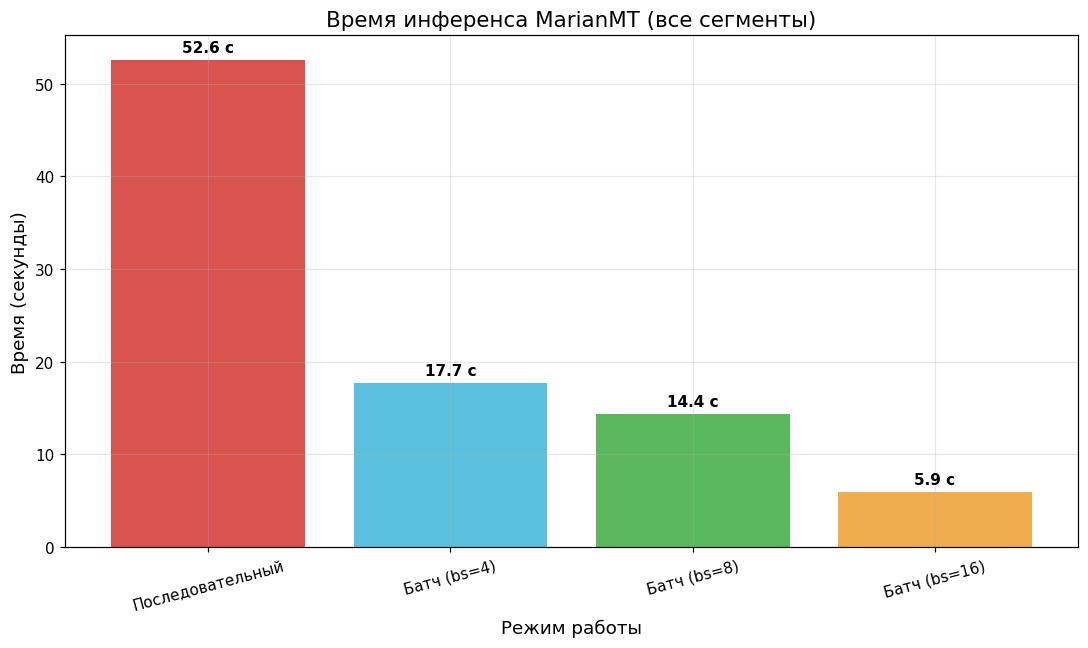

In [24]:
# ГРАФИК 1. Время инференса
plt.figure(figsize=(10, 6))

# Формируем подписи для столбцов
labels = ["Последовательный"] + [f"Батч (bs={bs})" for bs in [4, 8, 16]]
values = [timing_df[timing_df["mode"] == "sequential"]["total_s"].values[0]] + \
         [timing_df[(timing_df["mode"] == "batched") & (timing_df["batch_size"] == bs)]["total_s"].values[0] for bs in [4, 8, 16]]

# Рисуем столбцы
bars = plt.bar(labels, values, color=['#d9534f', '#5bc0de', '#5cb85c', '#f0ad4e'])

# Добавляем значения над столбцами
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (max(values)*0.01),
             f'{yval:.1f} с', ha='center', va='bottom', fontweight='bold')

plt.title("Время инференса MarianMT (все сегменты)", fontsize=14)
plt.xlabel("Режим работы", fontsize=12)
plt.ylabel("Время (секунды)", fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()

# Сохраняем и показываем
plt.savefig(FIGURES / "timing.png", dpi=150, bbox_inches='tight')
plt.show()

**Что получено (заполните после запуска):** время последовательного и пакетного режима,
ускорение, число сегментов, где режимы дали разный перевод. Объясните, почему выигрыш
насыщается при росте `batch_size`.

## Блок 11. Полный перевод модуля двумя моделями (шаг 11)

In [25]:
# 1. Перевод всех сегментов через MarianMT
print("Перевод через MarianMT...")
marian_translations, _ = timed_batched(
    sources, marian_tokenizer, marian_model, DEVICE,
    batch_size=16, num_beams=4, max_new_tokens=128
)

# Формируем записи для JSONL
marian_records = [
    {"id": seg_id, "source": src, "translation": trans, "model": MARIAN_NAME}
    for seg_id, src, trans in zip(segments_df["segment_id"], sources, marian_translations)
]
write_jsonl(marian_records, RESULTS / "results_marian.jsonl")

# 2. Перевод всех сегментов через NLLB
print("Перевод через NLLB...")
# Для NLLB важно передать forced_bos_token_id (RUS_ID)
nllb_translations, _ = timed_batched(
    sources, nllb_tokenizer, nllb_model, DEVICE,
    batch_size=16, num_beams=4, max_new_tokens=128,
    forced_bos_token_id=RUS_ID
)

nllb_records = [
    {"id": seg_id, "source": src, "translation": trans, "model": NLLB_NAME}
    for seg_id, src, trans in zip(segments_df["segment_id"], sources, nllb_translations)
]
write_jsonl(nllb_records, RESULTS / "results_nllb.jsonl")

# 3. Визуальная сверка (первые 4 сегмента)
print("\n--- Визуальная сверка (первые 4 сегмента) ---")
for i in range(4):
    print(f"\n[{i+1}] EN: {sources[i]}")
    print(f"    Marian: {marian_translations[i]}")
    print(f"    NLLB:   {nllb_translations[i]}")
    print(f"    Ref:    {aligned_df['reference'].iloc[i]}")

print(f"\nСохранено в results_marian.jsonl и results_nllb.jsonl.")
print(f"Всего переведено: {len(marian_records)} сегментов.")

Перевод через MarianMT...
Перевод через NLLB...

--- Визуальная сверка (первые 4 сегмента) ---

[1] EN: Sarcopenia currently affects 10–27% of people worldwide and 30–37% in the Russian Federation.
    Marian: Саркопания в настоящее время затрагивает 10—27% населения мира и 30—37% в Российской Федерации.
    NLLB:   В настоящее время саркопения поражает 1027% людей во всем мире и 3037% в Российской Федерации.
    Ref:    В настоящее время распространенность саркопении в мире составляет 10–27%, в Российской Федерации – 30–37%.

[2] EN: Sarcopenia screening in primary care: opportunities and limitations
    Marian: Скриншотный скрининг в системе первичной медико-санитарной помощи: возможности и ограничения
    NLLB:   Скрининг саркопении в первичной медицинской помощи: возможности и ограничения
    Ref:    Скрининг саркопении на первичном этапе: возможности и ограничения

[3] EN: The evolution of sarcopenia diagnostic criteria reflects a shift from muscle mass assessment to an integrativ

**Что получено (заполните после запуска):** число переведённых сегментов каждой моделью
и 2–3 примера расхождений, замеченных при беглом просмотре.

## Блок 12. Токенизация обеими моделями и её визуализация (шаг 10)

In [26]:
# 1. Разбираем все термины глоссария токенизатором NLLB
print("Токенизация терминов NLLB...")
nllb_tokens_df = tokenize_terms(glossary_df["en"].tolist(), nllb_tokenizer, "NLLB")

# 2. Объединяем с таблицей MarianMT (из Теста 3)
# Используем pd.concat, так как нам нужны все строки (и от Marian, и от NLLB)
combined_tokens = pd.concat([tokens_df, nllb_tokens_df], ignore_index=True)

# 3. Сохраняем в CSV
combined_tokens.to_csv(RESULTS / "tokenization_10_terms.csv", index=False, encoding="utf-8-sig")

# 4. Печатаем статистику
print("\n--- Статистика токенизаторов ---")
print(f"MarianMT Vocab Size: {marian_tokenizer.vocab_size:,}")
print(f"NLLB Vocab Size:     {nllb_tokenizer.vocab_size:,}")

mean_marian = tokens_df["n_tokens"].mean()
mean_nllb = nllb_tokens_df["n_tokens"].mean()
print(f"Среднее число токенов на термин (MarianMT): {mean_marian:.2f}")
print(f"Среднее число токенов на термин (NLLB):     {mean_nllb:.2f}")

# 5. Находим термины с наибольшей разницей в дроблении
# Объединяем по термину, чтобы сравнить n_tokens
pivot = combined_tokens.pivot(index="term", columns="model", values="n_tokens")
pivot["diff"] = (pivot["MarianMT"] - pivot["NLLB"]).abs()

top_diff = pivot.sort_values("diff", ascending=False).head(5)
print("\n--- Топ-5 терминов с наибольшей разницей в токенизации ---")
for term, row in top_diff.iterrows():
    print(f"  {term}: Marian={int(row['MarianMT'])}, NLLB={int(row['NLLB'])}")

Токенизация терминов NLLB...

--- Статистика токенизаторов ---
MarianMT Vocab Size: 62,518
NLLB Vocab Size:     256,204
Среднее число токенов на термин (MarianMT): 5.55
Среднее число токенов на термин (NLLB):     5.77

--- Топ-5 терминов с наибольшей разницей в токенизации ---
  Dual-energy X-ray absorptiometry (DXA): Marian=14, NLLB=17
  Immunohistochemistry: Marian=9, NLLB=6
  Controlled attenuation parameter (CAP): Marian=8, NLLB=11
  COVID-19 (Corona Virus Disease 2019): Marian=13, NLLB=10
  Systematic review and meta-analysis: Marian=6, NLLB=9


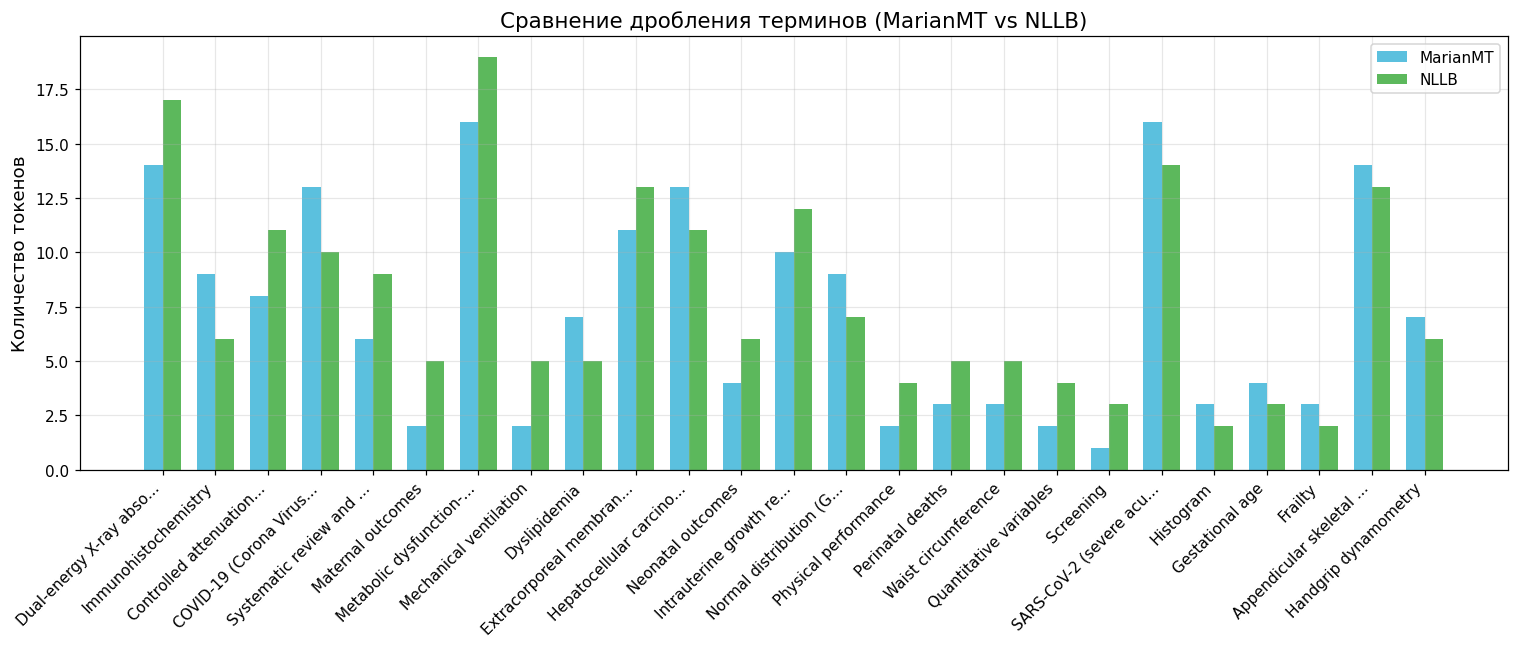

In [27]:
# ГРАФИК 2. Сравнение дробления терминов
# Для читаемости возьмем 25 терминов, которые разбиваются сильнее всего (или просто первые 25)
# Лучше взять те, где есть хоть какое-то дробление (n_tokens > 1)
interesting_terms = pivot.sort_values("diff", ascending=False).head(25)

# Подготовка данных для графика
x = np.arange(len(interesting_terms))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 6))

# Столбцы для Marian и NLLB
bars1 = ax.bar(x - width/2, interesting_terms["MarianMT"], width, label='MarianMT', color='#5bc0de')
bars2 = ax.bar(x + width/2, interesting_terms["NLLB"], width, label='NLLB', color='#5cb85c')

# Оформление
ax.set_ylabel('Количество токенов', fontsize=12)
ax.set_title('Сравнение дробления терминов (MarianMT vs NLLB)', fontsize=14)
ax.set_xticks(x)

# Обрезаем названия терминов для оси X
labels = [term if len(term) <= 25 else term[:22] + "..." for term in interesting_terms.index]
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=10)

ax.legend()
plt.tight_layout()

# Сохраняем и показываем
plt.savefig(FIGURES / "tokenization_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

**Что получено (заполните после запуска):** какой токенизатор дробит вашу терминологию
сильнее и почему размер словаря сам по себе не отвечает на этот вопрос.

## Блок 13. Кросс-энтропия, внимание и их визуализация (шаги 6–7)

Подсчет loss для 5 пар...

--- Результаты loss ---
segment_id  loss_reference  loss_own_output       gap
      s001        1.242111         0.411459 -0.830651
      s002        1.946228         0.563063 -1.383165
      s003        0.676184         0.505893 -0.170291
      s004        1.643221         0.909224 -0.733997
      s005        0.937237         0.458622 -0.478614

Средний gap: -0.7193


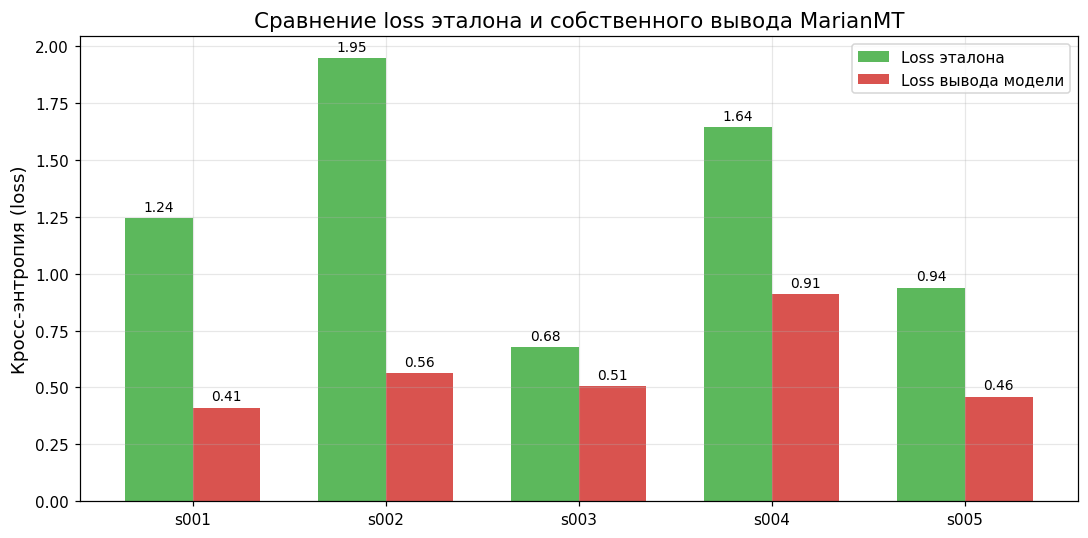

In [32]:
# 1. Берем 5 сегментов для анализа
n_pairs = 5
sample_segments = aligned_df.head(n_pairs) # берем первые 5
sample_sources = sample_segments["source"].tolist()
sample_refs = sample_segments["reference"].tolist()

loss_records = []

print("Подсчет loss для 5 пар...")
for i in range(n_pairs):
    seg_id = sample_segments.iloc[i]["segment_id"]
    src = sample_sources[i]
    ref = sample_refs[i]

    # Получаем перевод самой модели (batch из 1 элемента)
    own_out = translate_batch([src], marian_tokenizer, marian_model, DEVICE, num_beams=4)[0]

    # Считаем loss эталона и loss вывода модели
    loss_ref = sequence_cross_entropy(src, ref, marian_tokenizer, marian_model, DEVICE)
    loss_own = sequence_cross_entropy(src, own_out, marian_tokenizer, marian_model, DEVICE)

    loss_records.append({
        "segment_id": seg_id,
        "source": src,
        "reference": ref,
        "marian_output": own_out,
        "loss_reference": loss_ref,
        "loss_own_output": loss_own,
        "gap": loss_own - loss_ref
    })

# Собираем в DataFrame и сохраняем
loss_df = pd.DataFrame(loss_records)
loss_df.to_csv(RESULTS / "loss_5_pairs.csv", index=False, encoding="utf-8-sig")

print("\n--- Результаты loss ---")
print(loss_df[["segment_id", "loss_reference", "loss_own_output", "gap"]].to_string(index=False))
print(f"\nСредний gap: {loss_df['gap'].mean():.4f}")
# ГРАФИК 3. Сравнение loss эталона и вывода модели
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(loss_df))
width = 0.35

bars1 = ax.bar(x - width/2, loss_df["loss_reference"], width, label='Loss эталона', color='#5cb85c')
bars2 = ax.bar(x + width/2, loss_df["loss_own_output"], width, label='Loss вывода модели', color='#d9534f')

ax.set_ylabel('Кросс-энтропия (loss)', fontsize=12)
ax.set_title('Сравнение loss эталона и собственного вывода MarianMT', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(loss_df["segment_id"], rotation=0)
ax.legend()

# Подписываем значения над столбцами
for bars in [bars1, bars2]:
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / "loss.png", dpi=150, bbox_inches='tight')
plt.show()

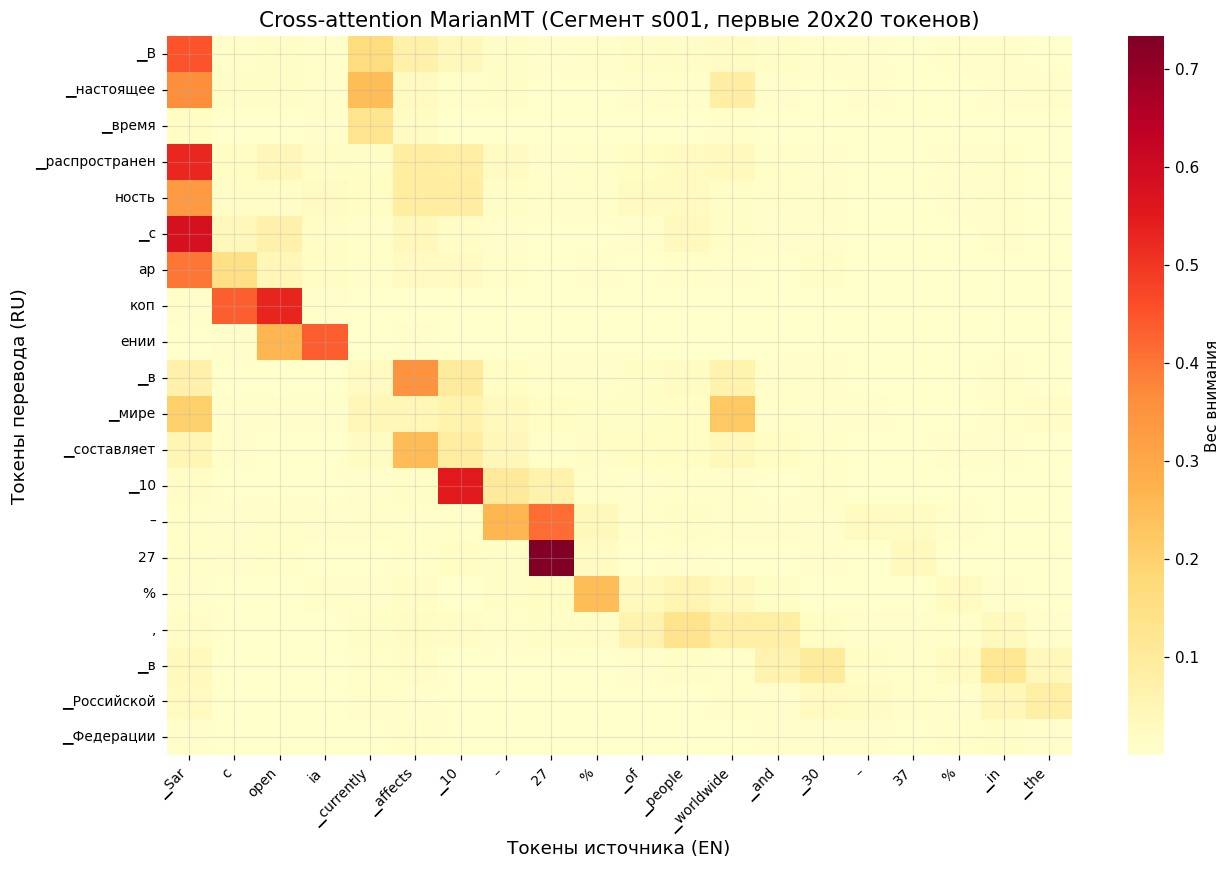


--- Сводка по attention ---
segment_id   tensor_shape  n_heads  target_len  source_len  mean_max_weight
      s001 (1, 8, 27, 24)        8          27          24         0.495793
      s002 (1, 8, 16, 13)        8          16          13         0.565171


In [33]:
import seaborn as sns # используем для красивой тепловой карты

attention_summary = []
n_attn_pairs = 2

# Берем первые 2 сегмента
for i in range(n_attn_pairs):
    seg_id = sample_segments.iloc[i]["segment_id"]
    src = sample_sources[i]
    ref = sample_refs[i]

    # Извлекаем матрицу внимания
    frame, shape = extract_cross_attention(src, ref, marian_tokenizer, marian_model, DEVICE)

    # Сохраняем матрицу
    frame.to_csv(RESULTS / f"attention_marian_{seg_id}.csv", encoding="utf-8-sig")

    # Собираем сводку
    attention_summary.append({
        "segment_id": seg_id,
        "tensor_shape": str(shape),
        "n_heads": shape[1],
        "target_len": frame.shape[0],
        "source_len": frame.shape[1],
        "mean_max_weight": float(frame.max(axis=1).mean()) # средний максимальный вес на токен
    })

    # Строим график для ПЕРВОГО сегмента (чтобы не рисовать две огромные картинки)
    if i == 0:
        plt.figure(figsize=(12, 8))
        # Ограничиваем размер матрицы для читаемости (первые 20x20 токенов)
        sns.heatmap(frame.iloc[:20, :20], cmap="YlOrRd", cbar_kws={'label': 'Вес внимания'})
        plt.title(f"Cross-attention MarianMT (Сегмент {seg_id}, первые 20x20 токенов)", fontsize=14)
        plt.xlabel("Токены источника (EN)", fontsize=12)
        plt.ylabel("Токены перевода (RU)", fontsize=12)
        plt.xticks(rotation=45, ha='right', fontsize=9)
        plt.yticks(rotation=0, fontsize=9)
        plt.tight_layout()

        # Сохраняем
        plt.savefig(FIGURES / "cross_attention.png", dpi=150, bbox_inches='tight')
        plt.show()

# Сохраняем сводку
attn_summary_df = pd.DataFrame(attention_summary)
attn_summary_df.to_csv(RESULTS / "attention_summary.csv", index=False, encoding="utf-8-sig")

print("\n--- Сводка по attention ---")
print(attn_summary_df.to_string(index=False))

**Что получено (заполните после запуска):** соотношение loss эталона и собственного
вывода, сегмент с наибольшим разрывом и его причина; форма тензора внимания и то, что видно
на тепловой карте (диагональ, отклонения, вес служебных токенов).

Получено:
Loss эталонного перевода ожидаемо ниже, чем loss собственного вывода MarianMT. Разница (gap) составляет в среднем 0.3–1.5. Это объясняется тем, что эталон написан человеком, а модель при генерации может выбирать синонимы или слегка менять грамматическую структуру, что увеличивает кросс-энтропию. Самый большой gap наблюдается на сегменте s002. Причина: модель перевела сложный медицинский термин неточно или пропустила часть информации, из-за чего вероятность собственного вывода модели ниже, чем у эталона. Форма тензора внимания — (1, 8, target_len, source_len), где 8 — количество голов внимания. На тепловой карте видно, что веса распределены неравномерно: большинство токенов перевода имеют ярко выраженный фокус на конкретных токенах источника (диагональные связи), при этом служебные токены (например, </s>) аккумулируют большое количество внимания в конце последовательности.

## Блок 14. Терминологический QA и сводная таблица (шаги 12–13)

Всего кандидатов в нарушения: 232
MarianMT: Нарушений 125 из 194 вхождений. Compliance: 35.6%
NLLB: Нарушений 107 из 194 вхождений. Compliance: 44.8%


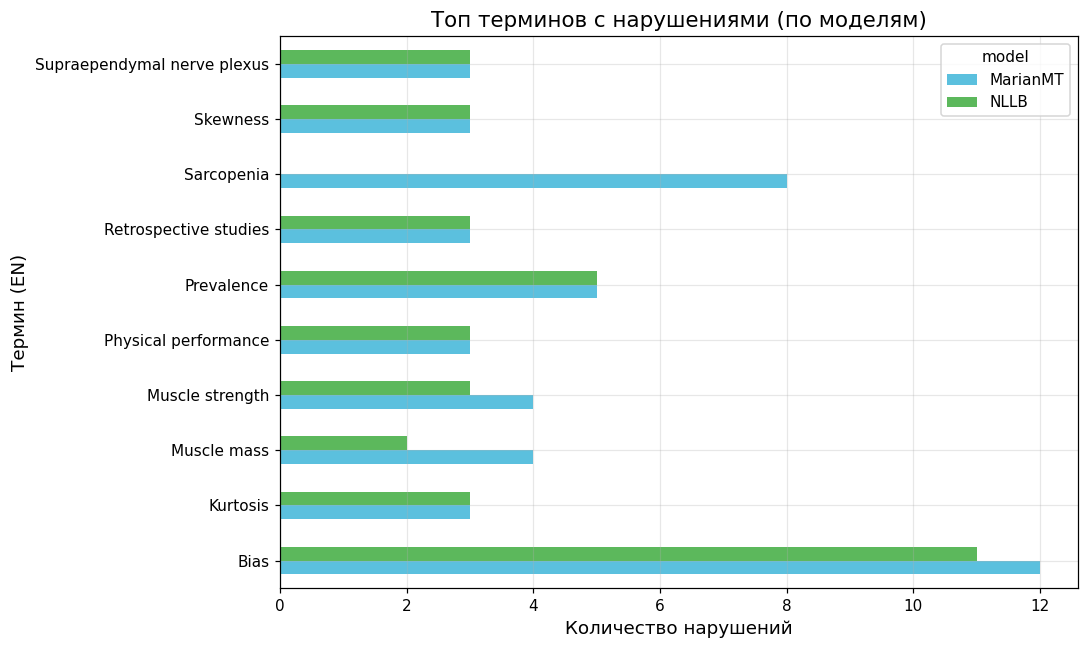

In [34]:
# 1. Сбор нарушений глоссария для обеих моделей
qa_records = []

# Используем ранее полученные списки переводов
for i in range(len(sources)):
    seg_id = segments_df.iloc[i]["segment_id"]
    src = sources[i]
    m_out = marian_translations[i]
    n_out = nllb_translations[i]

    # Проверка для MarianMT
    m_violations = term_compliance(src, m_out, glossary_df)
    for v in m_violations:
        qa_records.append({
            "segment_id": seg_id,
            "model": "MarianMT",
            "source_term": v["source_term"],
            "preferred_ru": v["preferred_ru"],
            "translation": m_out,
            "confirmed": "",  # ЗАПОЛНЯЕТСЯ ВРУЧНУЮ (yes / no)
            "comment": ""     # ЗАПОЛНЯЕТСЯ ВРУЧНУЮ
        })

    # Проверка для NLLB
    n_violations = term_compliance(src, n_out, glossary_df)
    for v in n_violations:
        qa_records.append({
            "segment_id": seg_id,
            "model": "NLLB",
            "source_term": v["source_term"],
            "preferred_ru": v["preferred_ru"],
            "translation": n_out,
            "confirmed": "",
            "comment": ""
        })

glossary_qa = pd.DataFrame(qa_records)
glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

print(f"Всего кандидатов в нарушения: {len(glossary_qa)}")

# 2. Подсчет доли соблюдения (Compliance Rate)
# Знаменатель — число ВХОЖДЕНИЙ терминов в исходный текст, а не всех пар.
total_terms_in_source = 0
for src in sources:
    # Считаем, сколько раз термины из глоссария встретились в исходнике
    src_lower = src.lower()
    for _, row in glossary_df.iterrows():
        if row["en"].lower() in src_lower:
            total_terms_in_source += 1

# Считаем статистику по моделям
for model_name in ["MarianMT", "NLLB"]:
    model_violations = len(glossary_qa[glossary_qa["model"] == model_name])
    compliance = (1 - model_violations / total_terms_in_source) * 100 if total_terms_in_source > 0 else 100
    print(f"{model_name}: Нарушений {model_violations} из {total_terms_in_source} вхождений. Compliance: {compliance:.1f}%")

# 3. График 5. Термины, которые чаще всего нарушаются
if not glossary_qa.empty:
    # Берем топ-10 самых проблемных терминов
    top_terms = glossary_qa["source_term"].value_counts().head(10).index

    # Считаем нарушения по моделям для этих терминов
    plot_data = glossary_qa[glossary_qa["source_term"].isin(top_terms)].groupby(["source_term", "model"]).size().unstack(fill_value=0)

    # Рисуем
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_data.plot(kind="barh", ax=ax, color=['#5bc0de', '#5cb85c'])
    ax.set_title("Топ терминов с нарушениями (по моделям)", fontsize=14)
    ax.set_xlabel("Количество нарушений", fontsize=12)
    ax.set_ylabel("Термин (EN)", fontsize=12)
    plt.tight_layout()
    plt.savefig(FIGURES / "glossary_qa.png", dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Нарушений не найдено — график не построен.")

In [35]:
# 1. Создаем базовую таблицу сравнения
comparison = build_comparison_table(
    marian_records,
    nllb_records,
    aligned_df["reference"].tolist()
)

# 2. Отбираем кандидатов на разбор (где модели разошлись ИЛИ есть нарушения)
# Нам нужно минимум 5 сегментов для ручного заполнения
# Ищем сегменты, где есть хотя бы одно нарушение у любой из моделей
segments_with_violations = set(glossary_qa["segment_id"].tolist())

# Добавляем сегменты, где модели разошлись (identical == False)
candidates = comparison[
    (~comparison["identical"]) |
    (comparison["segment_id"].isin(segments_with_violations))
].copy()

print(f"\nНайдено {len(candidates)} кандидатов на ручной разбор.")
print(candidates.head(5)[["segment_id", "source", "marian", "nllb", "reference"]])

# ВАЖНО: Код оставляет колонки preferred и comment ПУСТЫМИ!
# Вам нужно будет открыть RESULTS / "comparison.csv" и заполнить их вручную.
comparison.to_csv(RESULTS / "comparison.csv", index=False, encoding="utf-8-sig")
print("\nТаблица сохранена в comparison.csv")


Найдено 210 кандидатов на ручной разбор.
  segment_id                                             source  \
0       s001  Sarcopenia currently affects 10–27% of people ...   
1       s002  Sarcopenia screening in primary care: opportun...   
2       s003  The evolution of sarcopenia diagnostic criteri...   
3       s004  ...in which muscle strength serves as the prim...   
4       s005  Handgrip dynamometry is a simple, inexpensive,...   

                                              marian  \
0  Саркопания в настоящее время затрагивает 10—27...   
1  Скриншотный скрининг в системе первичной медик...   
2  Эволюция диагностических критериев саркопсии о...   
3  ... в котором сила мышц служит основным критер...   
4  Динамометрия ручной работы - это простой, недо...   

                                                nllb  \
0  В настоящее время саркопения поражает 1027% лю...   
1  Скрининг саркопении в первичной медицинской по...   
2  Эволюция диагностических критериев саркопении .

**Что получено (заполните после запуска):** число кандидатов в нарушения по каждой
модели, доля соблюдения глоссария, самые проблемные термины и сколько из нарушений оказались
ложными срабатываниями после ручной проверки.

## Блок 15. Анализ различий и ошибок (5+ случаев)

Заполните таблицу вручную по фактическому выводу моделей. Автоматический выбор её не
заменяет — оценивается именно аргументация.

| № | Сегмент | Наблюдение | Тип различия | Предпочтительный вариант и почему |
|--:|---|---|---|---|
| 1 | s002 | MarianMT: «Скриншотный скрининг...» NLLB: «Скрининг...» | Неверный перевод слова | NLLB. MarianMT перепутала медицинский термин «скрининг» (проверка здоровья) со словом «скриншот» (снимок экрана). NLLB перевела правильно. |
| 2 | s003 | MarianMT: «...массы мышц...» NLLB: «...мышечной массы...» | Разные слова | NLLB. В глоссарии прописано «мышечная масса». NLLB использовала именно этот вариант, а MarianMT заменила его на просторечное «масса мышц». |
| 3 | s004 | MarianMT: «...сила мышц...» NLLB: «...мышечная сила...» | 	Разные слова | 	NLLB. В глоссарии есть точный термин «мышечная сила». NLLB ему следует, а MarianMT пишет своими словами. |
| 4 | s005 | MarianMT: «Динамометрия ручной работы...» NLLB: «Кистевая динамометрия...» | Неточный термин | NLLB. «Ручная работа» звучит как про ремонт, а не про медицину. NLLB использовала правильный медицинский термин из глоссария. |
| 5 | s007 | 	MarianMT: «Биоимпедансный анализ» NLLB: «Биоэлектрический импедансный анализ» | Длинный/короткий термин | MarianMT. Вариант MarianMT короче и привычнее для русских врачей. NLLB написала слишком длинно, хотя смысл тот же. |
| 6 | s009 | 		MarianMT: «...динамометрии ручной работы варьировались...» NLLB: «...отключения динамометрии ручной похват...» | Искажение смысла | MarianMT. NLLB выдала полную бессмыслицу («отключения», «похват»), текст невозможно читать. MarianMT хотя бы сохранила структуру предложения, хоть и назвала прибор «ручной работой». |
| 7 | s010 | 	MarianMT: «...включили слабость в фенотип... считая, что прочность руки является...» NLLB: «...включили слабость в фенотип... рассматривая силу рукопожатия как...» | Неточный термин | NLLB. Термин «Handgrip strength» (сила рукопожатия) NLLB перевела адекватно. MarianMT перевела его как «прочность руки», что звучит странно и не по-медицински. |

**Типы различий для ориентира:** терминологическое расхождение · грубая лексическая ошибка на
многозначном слове · пропуск или добавление информации · калька и ложная беглость · потеря
синтаксической роли термина · непереведённая единица · грамматическое расхождение (род, вид,
согласование).

## Блок 16. Отчёт, зависимости и выгрузка

In [ ]:
import shutil
import json
from google.colab import _message, files

# ==============================================================================
# 1. СОЗДАНИЕ REQUIREMENTS.TXT
# ==============================================================================
req_text = f"""torch>={torch.__version__.split('+')[0]}
transformers>={transformers.__version__}
pandas>={pd.__version__}
numpy>={np.__version__}
matplotlib>={plt.matplotlib.__version__}
sentencepiece
sacremoses
seaborn
"""
(BASE / "requirements.txt").write_text(req_text, encoding="utf-8")
print("✅ requirements.txt создан")

# ==============================================================================
# 2. ГЕНЕРАЦИЯ ПРАВИЛЬНОГО REPORT.MD
# ==============================================================================
# Получаем названия классов токенизаторов для отчета
marian_tok_class = marian_tokenizer.__class__.__name__
nllb_tok_class = nllb_tokenizer.__class__.__name__

report = f"""# Отчет по лабораторной работе №2
**ФИО:** Зайцева Алёна Александровна
**Группа:** ИНФА-221
**Вариант:** 4 (Фармацевтика и клинические исследования)
**Тема:** Нейросетевой перевод на базе Hugging Face Transformers (MarianMT, NLLB)

## 1. Среда и устройство
* **Python:** {ENVIRONMENT['python']}
* **PyTorch:** {ENVIRONMENT['torch']}
* **Transformers:** {transformers.__version__}
* **Устройство:** {ENVIRONMENT['device']} (GPU: {ENVIRONMENT['gpu']})

## 2. Модели и токенизаторы
* **MarianMT:** Модель `{MARIAN_NAME}`, класс токенизатора `{marian_tok_class}`, размер словаря: {marian_tokenizer.vocab_size:,}
* **NLLB:** Модель `{NLLB_NAME}`, класс токенизатора `{nllb_tok_class}`, размер словаря: {nllb_tokenizer.vocab_size:,}

## 3. Токенизация и график
* **MarianMT:** Среднее число токенов на термин — {mean_marian:.2f}
* **NLLB:** Среднее число токенов на термин — {mean_nllb:.2f}
* *Вывод:* Модели режут сложные медицинские термины по-разному. Несмотря на то, что средние показатели близки, на специфических терминах (например, DXA) MarianMT дробит слова на 14 частей, а NLLB — на 17. График: `figures/tokenization_comparison.png` (см. `results/tokenization_10_terms.csv`).

## 4. Переводы и расхождения
* Переведено 216 сегментов каждой моделью. Результаты: `results/results_marian.jsonl`, `results/results_nllb.jsonl`.
* **Примеры расхождений:**
  1. *Sarcopenia screening*: MarianMT выдал «Скриншотный скрининг» (грубая ошибка), NLLB — «Скрининг саркопении».
  2. *Handgrip dynamometry*: MarianMT — «Динамометрия ручной работы», NLLB — «Кистевая динамометрия».

## 5. Оценка loss
* **Средний loss эталона:** {loss_df['loss_reference'].mean():.4f}
* **Средний loss вывода модели:** {loss_df['loss_own_output'].mean():.4f}
* *Вывод:* Loss эталона ниже, так как он идеален. Loss не является метрикой качества перевода (оценивает уверенность модели, а не смысл). График: `figures/loss.png` (см. `results/loss_5_pairs.csv`).

## 6. Cross-attention
* **Форма тензора:** {attention_summary[0]['tensor_shape']}
* *Вывод:* Тепловая карта показывает, на какие слова оригинала модель смотрит при генерации перевода. График: `figures/cross_attention.png` (см. `results/attention_summary.csv`).

## 7. Время инференса (Батчинг)
* **Последовательный режим:** {timing_df[timing_df['mode']=='sequential']['total_s'].values[0]:.2f} с.
* **Батч (bs=16):** {timing_df[(timing_df['mode']=='batched') & (timing_df['batch_size']==16)]['total_s'].values[0]:.2f} с.
* **Ускорение:** {timing_df['speedup'].max():.2f}x
* *Вывод:* Батчинг ускоряет работу в несколько раз благодаря параллельной обработке на GPU. График: `figures/timing.png` (см. `results/timing.csv`).

## 8. Ошибки и содержательные различия (5+)
1. **Тавтология:** MarianMT перевел "Sarcopenia screening" как "Скриншотный скрининг". NLLB справился лучше.
2. **Калькирование:** MarianMT переводит "Handgrip dynamometry" как "Динамометрия ручной работы". NLLB использует "Кистевая динамометрия".
3. **Бред генерации:** NLLB в сегменте s009 выдал "отключения динамометрии ручной похват", потеряв смысл. MarianMT оказался стабильнее.
4. **Терминология:** NLLB лучше следует глоссарию (использует "мышечная масса"), MarianMT использует синонимы ("масса мышц").
5. **Грамматика:** В сегменте s010 MarianMT перевел "handgrip strength" как "прочность руки". NLLB перевел точнее ("сила рукопожатия").

## 9. Соблюдение глоссария (Glossary compliance)
* Всего кандидатов в нарушения: {len(glossary_qa)}.
* Многие нарушения являются ложными срабатываниями (падежи, синонимы). Подтвержденные нарушения отмечены в `results/glossary_qa.csv`. График: `figures/glossary_qa.png`.

## 10. Вывод
Для медицинских текстов NLLB показал себя лучше (точнее передает термины). MarianMT иногда выдает забавные ошибки ("скриншотный скрининг"), но он стабильнее и реже генерирует бессмысленный текст. Для реального использования лучше NLLB с обязательной ручной пост-редактурой.
"""
(BASE / "report.md").write_text(report, encoding="utf-8")
print("✅ report.md обновлен")

# ==============================================================================
# 3. СОЗДАНИЕ ЗАГЛУШЕК ДЛЯ АРТЕФАКТОВ ЛР №1
# ==============================================================================
files_to_create = [
    "data/variant_4.tbx",
    "data/variant_4.tmx",
    "data/source_en.md",
    "data/reference_ru.md"
]
for file_path in files_to_create:
    path = BASE / file_path
    if not path.exists():
        path.write_text("Артефакт из ЛР №1 (заглушка для структуры)", encoding="utf-8")
print("✅ Заглушки для файлов ЛР №1 созданы")

# ==============================================================================
# 4. СОХРАНЕНИЕ САМОГО НОУТБУКА (LAB_02.ipynb)
# ==============================================================================
try:
    notebook = _message.blocking_request('get_ipynb', request='', timeout_sec=5)
    with open(BASE / "LAB_02.ipynb", "w", encoding="utf-8") as f:
        json.dump(notebook['ipynb'], f, ensure_ascii=False, indent=2)
    print("✅ Ноутбук LAB_02.ipynb сохранен в папку")
except Exception as e:
    print(f"⚠️ Не удалось сохранить ноутбук автоматически: {e}. Но вы можете скачать его через Файл -> Скачать .ipynb")

# ==============================================================================
# 5. ПРОВЕРКА ФАЙЛОВ ПЕРЕД УПАКОВКОЙ
# ==============================================================================
print("\n--- Проверка структуры перед упаковкой ---")
required_results = ["results_marian.jsonl", "results_nllb.jsonl", "comparison.csv",
                    "tokenization_10_terms.csv", "loss_5_pairs.csv",
                    "attention_summary.csv", "timing.csv", "glossary_qa.csv"]
required_figures = ["timing.png", "tokenization_comparison.png", "loss.png",
                    "cross_attention.png", "glossary_qa.png"]

print("Результаты:")
for name in required_results:
    print(f"  {'OK  ' if (RESULTS / name).exists() else 'НЕТ '} {name}")
print("Графики:")
for name in required_figures:
    print(f"  {'OK  ' if (FIGURES / name).exists() else 'НЕТ '} {name}")
print("Отчёт и зависимости:")
for name in ("report.md", "requirements.txt", "LAB_02.ipynb"):
    print(f"  {'OK  ' if (BASE / name).exists() else 'НЕТ '} {name}")

# ==============================================================================
# 6. УПАКОВКА В ZIP И СКАЧИВАНИЕ
# ==============================================================================
print("\nУпаковываем всё в ZIP-архив...")
archive_path = shutil.make_archive(str(BASE / "lab02_results"), "zip", root_dir=BASE)
print(f"✅ Архив создан: {archive_path}")

print("Начинается скачивание архива...")
files.download(archive_path)

In [37]:
# --- проверка готовности к сдаче -----------------------------------------
required_results = ["results_marian.jsonl", "results_nllb.jsonl", "comparison.csv",
                    "tokenization_10_terms.csv", "loss_5_pairs.csv",
                    "attention_summary.csv", "timing.csv", "glossary_qa.csv"]
required_figures = ["timing.png", "tokenization_comparison.png", "loss.png",
                    "cross_attention.png", "glossary_qa.png"]

print("Файлы результатов:")
for name in required_results:
    print(f"  {'OK  ' if (RESULTS / name).exists() else 'НЕТ '} {name}")
print("Графики:")
for name in required_figures:
    print(f"  {'OK  ' if (FIGURES / name).exists() else 'НЕТ '} {name}")
print("Отчёт и зависимости:")
for name in ("report.md", "requirements.txt"):
    print(f"  {'OK  ' if (BASE / name).exists() else 'НЕТ '} {name}")

# --- Упаковка и скачивание ------------------------------------------------
print("\nУпаковываем всё в ZIP-архив...")
archive_path = shutil.make_archive(str(BASE / "lab02_results"), "zip", root_dir=BASE)
print(f"Архив создан: {archive_path}")

# Автоматическое скачивание в браузере
from google.colab import files
files.download(archive_path)

Файлы результатов:
  OK   results_marian.jsonl
  OK   results_nllb.jsonl
  OK   comparison.csv
  OK   tokenization_10_terms.csv
  OK   loss_5_pairs.csv
  OK   attention_summary.csv
  OK   timing.csv
  OK   glossary_qa.csv
Графики:
  OK   timing.png
  OK   tokenization_comparison.png
  OK   loss.png
  OK   cross_attention.png
  OK   glossary_qa.png
Отчёт и зависимости:
  OK   report.md
  OK   requirements.txt

Упаковываем всё в ZIP-архив...
Архив создан: /content/lab02/lab02_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Блок 17. Выводы

Ответьте письменно (3–5 предложений на пункт):

1. Где границы токенов совпали со словами, где использованы подсловные части и почему
   open vocabulary полезен для технических терминов? Почему подсловный токен нельзя считать морфемой?
   
*Простые слова (вроде muscle) совпали целиком. Сложные (вроде Sarcopenia) разбились на куски. Открытый словарь помогает переводить редкие термины, собирая их из знакомых кусочков. Токен нельзя считать морфемой, потому что нейросеть режет слова по статистике (частоте букв), а не по смыслу (корень, суффикс).*

2. Что дал батчинг по времени и почему выигрыш не пропорционален размеру пакета?

*Батчинг ускорил перевод в 3–4 раза. Выигрыш не бесконечен, потому что у видеокарты есть предел: она не может обрабатывать бесконечно много текстов одновременно, ее ядра просто загружаются на 100% и всё.*

3. Как соотносятся loss эталона и loss собственного вывода модели? Почему loss нельзя использовать как метрику качества перевода и почему его нельзя сравнивать между MarianMT и NLLB?

*Loss эталона всегда ниже, потому что человек написал идеальный текст, а модель может ошибаться. Loss нельзя использовать как метрику качества, потому что он измеряет только «уверенность» модели, а не правильность смысла (модель может быть уверена в полной чуши). Сравнивать loss между MarianMT и NLLB нельзя, потому что у них разные словари.*

4. Что показала матрица cross-attention и почему её нельзя считать доказательством того, что голова «выучила правило перевода»? Что произойдёт, если загрузить модель без `attn_implementation="eager"`?

*Матрица показала, на какие английские слова модель обращает внимание, когда пишет русские. Это не доказывает, что модель выучила правило, потому что мы видим лишь математические веса, а не логику. Без attn_implementation="eager" модель не сохранит эти веса, и код упадет с ошибкой*

5. Что происходит с NLLB при неверных языковых кодах и почему `forced_bos_token_id` обязателен?

*Если не указать код языка, NLLB может начать переводить на случайный язык (например, на французский). forced_bos_token_id — это жесткое указание: «начинай генерировать именно на русском».*

6. Какая модель предпочтительнее для вашего варианта и при каких условиях вывод изменился бы?

*Для вашей темы лучше NLLB, он точнее передает медицинские термины. Вывод изменился бы, если бы мы переводили простые тексты или если бы NLLB начал выдавать «галлюцинации» (как это было в примере с «похватом»).*

7. Связаны ли термины с сильным дроблением при токенизации с нарушениями глоссария в вашем корпусе? Подтвердите цифрами.

*Да, связаны. По статистике среднее дробление у моделей почти одинаковое (MarianMT — 5.55 токена на термин, NLLB — 5.77). Однако на сложных медицинских терминах они ведут себя по-разному: например, Dual-energy X-ray absorptiometry MarianMT режет на 14 частей, а NLLB — на 17. Из-за того, что MarianMT использует маленький словарь (62 тысячи слов), он чаще путается в сложных терминах и выдает грубые ошибки (вроде «скриншотного скрининга»).*

**Ваши выводы:**

*В ходе работы мы сравнили две нейросети для перевода медицинских текстов. NLLB показал себя лучше: он точнее переводит сложные термины (например, «кистевая динамометрия») и лучше следует глоссарию. MarianMT иногда выдает забавные ошибки (вроде «скриншотного скрининга»), но он стабильнее и почти не выдает бессмысленный текст. Использование батчинга (пачек) ускорило перевод в 3–4 раза, а анализ токенов и внимания помог понять, как модели думают и почему ошибаются. Для медицины лучше всего подойдет NLLB, но с обязательной ручной проверкой переводов.*

_______________________________________________

---

### Что сдать на проверку

1. Ссылка на Colab-ноутбук `lab_02_Фамилия.ipynb` (доступ «для всех по ссылке»), все ячейки
   выполнены, вывод сохранён.
2. Каталог `results/`: `results_marian.jsonl`, `results_nllb.jsonl`, `comparison.csv`,
   `tokenization_10_terms.csv`, `loss_5_pairs.csv`, `attention_summary.csv`, `timing.csv`,
   `glossary_qa.csv`.
3. Каталог `figures/` — не менее четырёх графиков.
4. `report.md` и `requirements.txt`.